***📓 Assignment-6: Myanmar ↔ Hieroglyph NMT — Complete Google Colab Notebook***

# Assignment-6: Myanmar ↔ Hieroglyph Neural Machine Translation
## မြန်မာစာ ↔ ဟိအဲရိုးဂလစ်ဖ် ဘာသာပြန်စနစ်

**Student**:AUNG KO KO OO

**Date**:Oct 11 2026

**Instructor**: Professor Dr. Ye Kyaw Thu

---

## ၁။ နိဒါန်း

ဒီ assignment ရဲ့ ရည်ရွယ်ချက်က **မြန်မာစာ** နဲ့ **ဟိအဲရိုးဂလစ်ဖ်** အကြား အပြန်အလှန် ဘာသာပြန်နိုင်တဲ့ **Neural Machine Translation (NMT)** စနစ်တစ်ခုကို **Marian NMT** framework သုံးပြီး တည်ဆောက်ဖို့ ဖြစ်ပါတယ်။

### လုပ်ဆောင်ရမည့်အချက်များ

| အချက် | ရှင်းလင်းချက် |
|--------|--------------|
| ဘာသာပြန်ဦးတည်ချက် | မြန်မာ → ဟိအဲရိုး နှင့် ဟိအဲရိုး → မြန်မာ |
| Framework | Marian NMT |
| Architecture | Seq2Seq (RNN) နှင့် Transformer |
| ထပ်ဆောင်း | Ensemble Approach |
| Evaluation | BLEU Score |

### အသုံးပြုမည့် ကိရိယာများ

- **Marian NMT** — Neural Machine Translation framework
- **SentencePiece** — Subword tokenization
- **sacrebleu** — BLEU score တွက်ချက်ရန်
- **Google Colab** — Training environment

In [ ]:
# ============================================================
# STEP 1: SETUP & INSTALL
# ============================================================
print("=" * 60)
print("STEP 1: SETUP & INSTALL")
print("=" * 60)

# Install Python packages
!pip install sentencepiece sacrebleu pandas matplotlib -q

# Install system dependencies for Marian
!apt-get install -y cmake build-essential libboost-all-dev libssl-dev -qq 2>&1 | tail -1

# Install Myanmar font (for visualization)
!apt-get install -y fonts-noto-core -qq 2>&1 | tail -1

import os, subprocess, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sentencepiece as spm
import sacrebleu
from collections import Counter

print("✅ sentencepiece:", spm.__version__)
print("✅ sacrebleu:", sacrebleu.__version__)
print("✅ Setup complete")

STEP 1: SETUP & INSTALL
✅ sentencepiece: 0.2.2
✅ sacrebleu: 2.6.0
✅ Setup complete


## 2. Compiling Marian NMT / ၂။ Marian NMT Compile လုပ်ခြင်း

**English:**  
Marian NMT is a C++ Neural Machine Translation framework supporting both Seq2Seq and Transformer architectures. We compile it in CPU mode because Colab's CUDA version may conflict with Marian's.

**မြန်မာ:**  
**Marian NMT** သည် C++ ဖြင့် ရေးသားထားသော Neural Machine Translation framework ဖြစ်ပြီး Seq2Seq နှင့် Transformer နှစ်မျိုးစလုံးကို support လုပ်ပါသည်။ Colab ရဲ့ CUDA version နဲ့ မကိုက်ညီနိုင်တာမို့ **CPU mode** ဖြင့် compile လုပ်ပါမည်။

### Compile Options

| Option | Meaning / အဓိပ္ပါယ် |
|--------|-------------------|
| `-DCOMPILE_CPU=on` | Compile for CPU |
| `-DCOMPILE_CUDA=off` | Disable CUDA (GPU) |
| `-DUSE_SENTENCEPIECE=on` | Enable SentencePiece |
| `-DCMAKE_BUILD_TYPE=Release` | Optimized build |

### Steps / အဆင့်များ

1. Clone from GitHub
2. **Update submodules** ⚠️ (critical)
3. CMake configure
4. `make` to compile (5–10 min)

In [ ]:
# ============================================================
# STEP 2: COMPILE MARIAN NMT
# ============================================================
print("=" * 60)
print("STEP 2: COMPILE MARIAN NMT")
print("=" * 60)

%cd /content

if not os.path.exists('/content/marian/build/marian'):
    !rm -rf /content/marian
    !git clone https://github.com/marian-nmt/marian.git -q
    %cd /content/marian
    !git submodule update --init --recursive -q
    !mkdir -p build
    %cd /content/marian/build

    print("⚙️  CMake configure...")
    !cmake .. -DCOMPILE_CPU=on -DCOMPILE_CUDA=off -DUSE_SENTENCEPIECE=on -DCMAKE_BUILD_TYPE=Release > /dev/null 2>&1

    print("🔨 Compiling (5-10 min)...")
    !make -j$(nproc) > /dev/null 2>&1

MARIAN_BIN = '/content/marian/build/marian'
MARIAN_DECODER = '/content/marian/build/marian-decoder'

if os.path.exists(MARIAN_BIN):
    print(f"✅ Marian binary: {MARIAN_BIN}")
    !{MARIAN_BIN} --version
else:
    print("❌ Marian compile failed!")

STEP 2: COMPILE MARIAN NMT
/content
✅ Marian binary: /content/marian/build/marian
v1.12.0 65bf82ff 2023-02-21 09:56:29 -0800


## 3. Downloading Data / ၃။ ဒေတာ ရယူခြင်း

**English:**  
We download the Myanmar–Hieroglyph parallel corpus from GitHub. The dataset contains:
- **train**: 8,500 sentences
- **valid**: 1,000 sentences
- **test**: 500 sentences

**မြန်မာ:**  
Myanmar–Hieroglyph parallel corpus ကို GitHub မှ download လုပ်ပါမည်။
- **train**: စာကြောင်း ၈,၅၀၀
- **valid**: စာကြောင်း ၁,၀၀၀
- **test**: စာကြောင်း ၅၀၀

### Sample / နမူနာ

| Myanmar / မြန်မာ | Hieroglyph / ဟိအဲရိုး |
|-------------------|------------------------|
| အချစ်က နာကျင်စေတယ်။ | 𓂋𓐍𓎼𓂝 𓊪𓎡𓋴𓈎𓈙 |

In [ ]:
# ============================================================
# STEP 3: DOWNLOAD DATA
# ============================================================
print("=" * 60)
print("STEP 3: DOWNLOAD DATA")
print("=" * 60)

%cd /content

if not os.path.exists('/content/AIE-F-B2/assignment/assignment-6/myhi_data/train.my'):
    !rm -rf /content/AIE-F-B2
    !git clone https://github.com/ye-kyaw-thu/AIE-F-B2.git -q

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print(f"✅ Data dir: {DATA_DIR}\n")
!ls -la *.my *.hi
print("\n📊 Line counts:")
!wc -l *.my *.hi

print("\n📄 Sample (train.my):")
!head -3 train.my
print("\n📄 Sample (train.hi):")
!head -3 train.hi

STEP 3: DOWNLOAD DATA
/content
✅ Data dir: /content/AIE-F-B2/assignment/assignment-6/myhi_data

-rw-r--r-- 1 root root 485942 Oct 10 14:54 all.hi
-rw-r--r-- 1 root root 590862 Oct 10 14:54 all.my
-rw-r--r-- 1 root root  24117 Oct 10 14:54 test.hi
-rw-r--r-- 1 root root  29994 Oct 10 14:54 test.my
-rw-r--r-- 1 root root 412919 Oct 10 14:54 train.hi
-rw-r--r-- 1 root root 502978 Oct 10 14:54 train.my
-rw-r--r-- 1 root root  48906 Oct 10 14:54 valid.hi
-rw-r--r-- 1 root root  57890 Oct 10 14:54 valid.my

📊 Line counts:
  10000 all.my
    500 test.my
   8500 train.my
   1000 valid.my
  10000 all.hi
    500 test.hi
   8500 train.hi
   1000 valid.hi
  40000 total

📄 Sample (train.my):
မင်းက အေးဆေးတယ်
ရိုးသားမှုရှိတယ်
ကျွန်မ ရိုးသားနိုင်လား။

📄 Sample (train.hi):
𓂨𓀀𓎡𓋴𓂝 𓏮𓀀𓐍𓂋
𓏏𓂝𓋴𓂝 𓈙𓆑𓎛𓏭𓂝𓋴𓂝
𓏭𓄿𓎛 𓆑 𓇋𓂝 𓊪𓐍𓎛𓂝𓈙𓈎


## 4. Data Visualization / ၄။ ဒေတာ လေ့လာခြင်း

**English:**  
Before building a translation model, we must understand our dataset. Visualization helps us check:
- Data quality and balance
- Sentence length distribution
- Source–target length correlation
- Vocabulary size

**မြန်မာ:**  
Machine Translation မော်ဒယ် တည်ဆောက်ခင် **ဒေတာကို အရင် လေ့လာဖို့ အလွန်အရေးကြီးပါသည်**။ Visualization က အောက်ပါအချက်များကို စစ်ဆေးနိုင်စေပါသည်:
- ဒေတာ အရည်အသွေးနှင့် balance
- စာကြောင်း အရှည် ဖြန့်ဖြူးမှု
- Source–Target အရှည် ဆက်စပ်မှု
- Vocabulary အရေအတွက်

### What We Visualize / လေ့လာမည့်အချက်များ

| Chart | Purpose / ရည်ရွယ်ချက် |
|-------|---------------------|
| Bar + Pie | Data split sizes |
| Histograms | Sentence length distribution |
| Scatter plots | Length correlation |
| Top-20 bar | Frequent characters/tokens |
| Zipf's Law | Natural language property |
| Sample table | Data quality check |

### How to Read the Results / ရလဒ်ဖတ်နည်း

- **Pearson r > 0.7** → Good source–target correlation
- **Unique chars** for Myanmar ≈ 50–150
- **Zipf's Law** plot should be roughly linear on log-log

STEP 4: DATA VISUALIZATION

📊 Data loaded:
  train: my=8500, hi=8500
  valid: my=1000, hi=1000
  test: my=500, hi=500


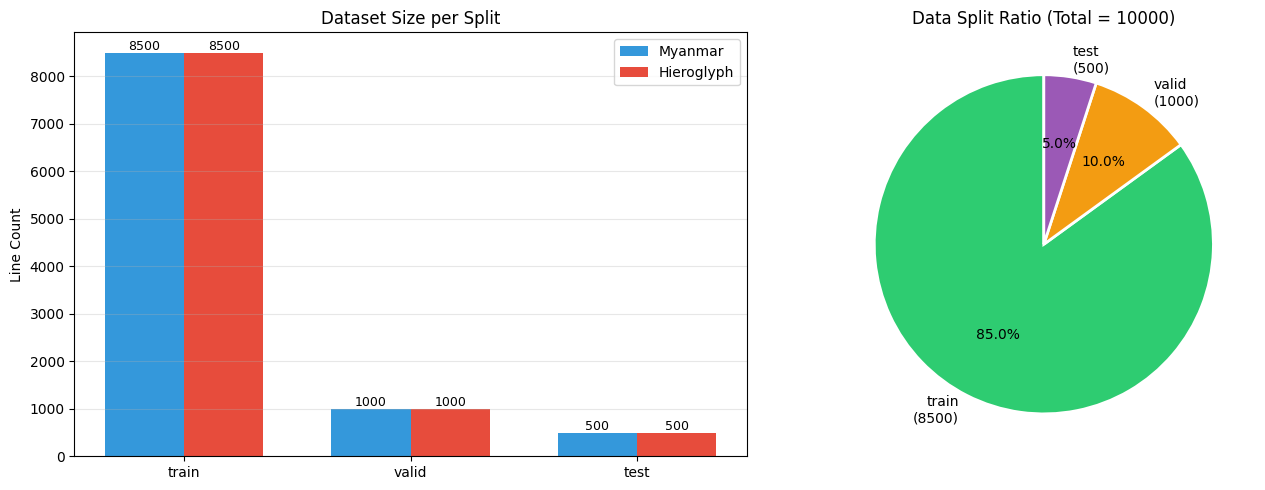

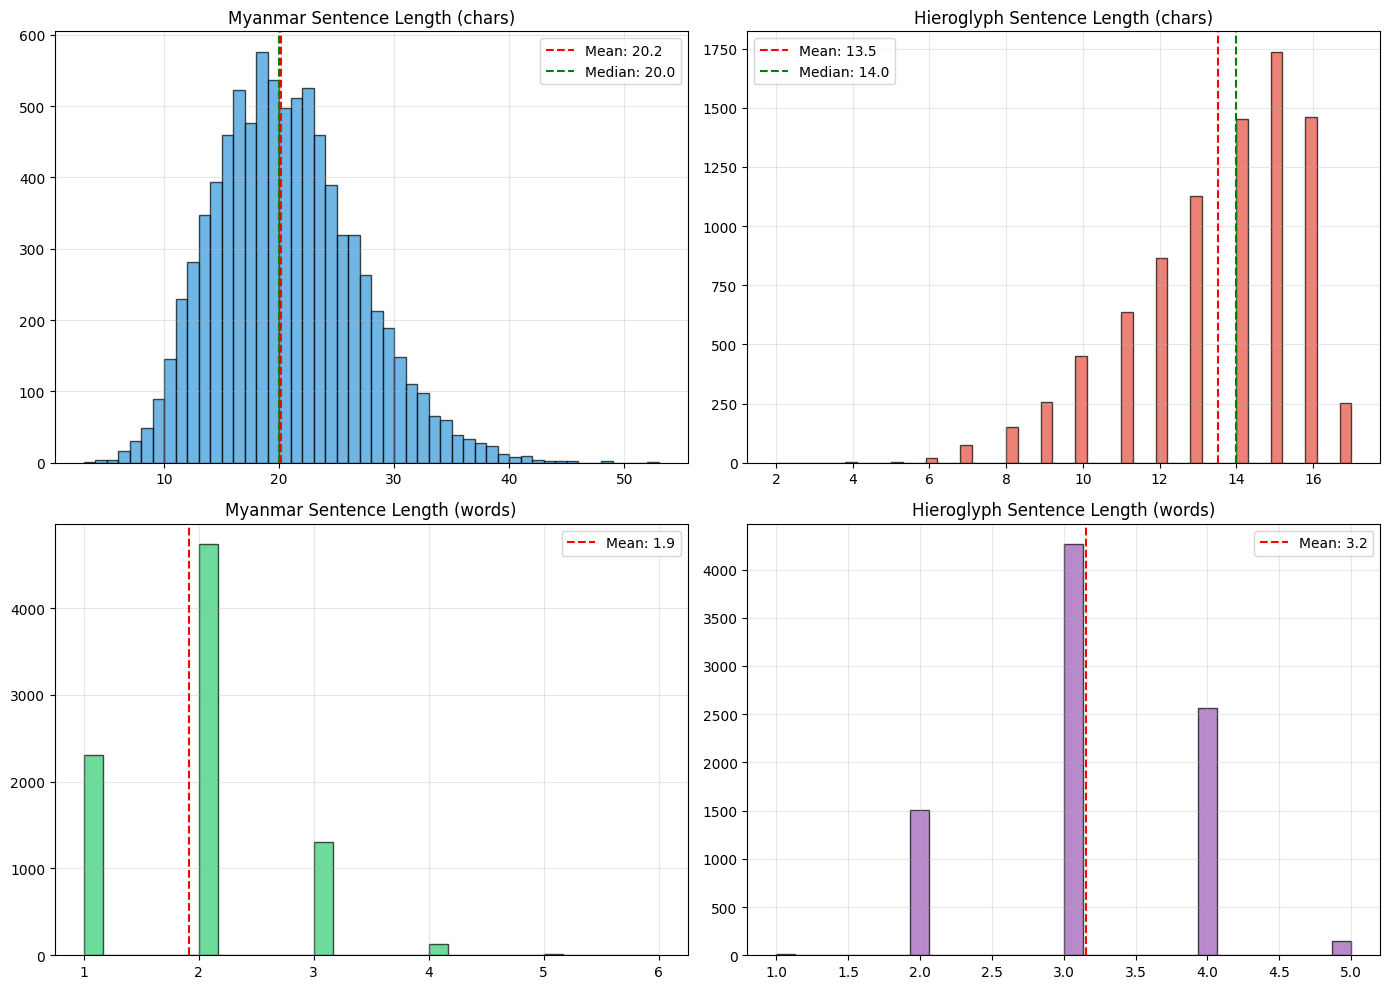

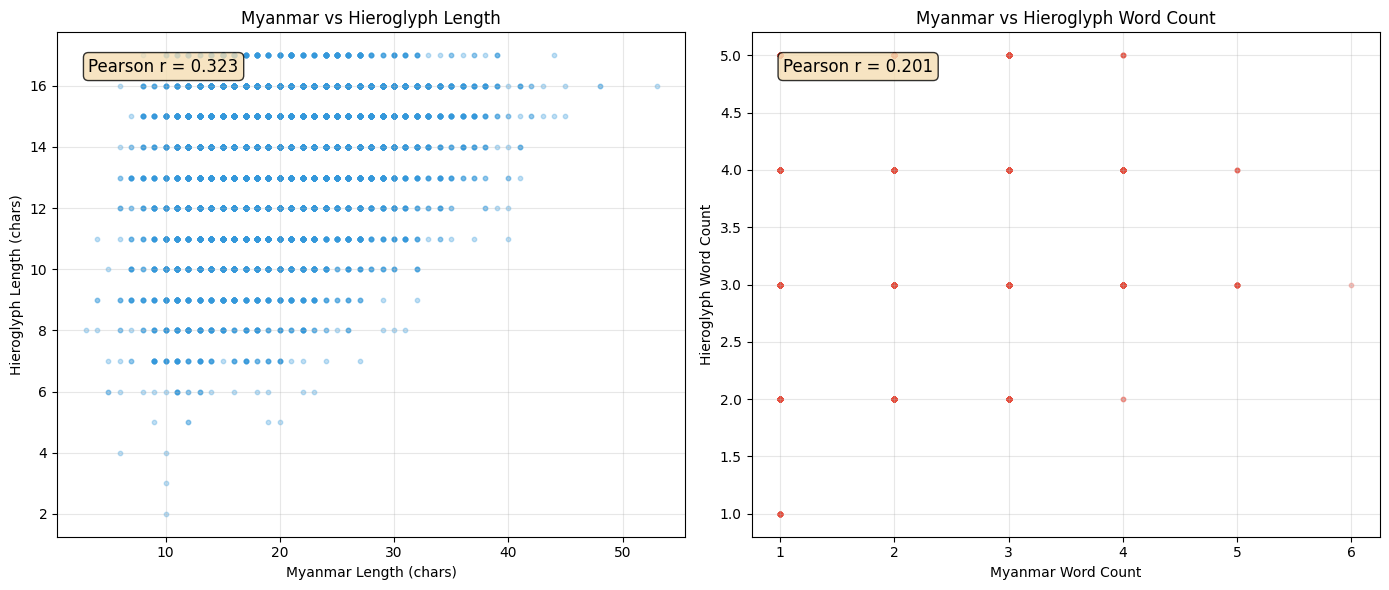


📚 VOCABULARY ANALYSIS

[Myanmar]
  Total chars:  163,579
  Unique chars: 109
  Total words:  16,322
  Unique words: 7,049

[Hieroglyph]
  Total tokens:  26,835
  Unique tokens: 2,858


/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4154 (\N{MYANMAR SIGN ASAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4096 (\N{MYANMAR LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4140 (\N{MYANMAR VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4112 (\N{MYANMAR LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4152 (\N{MYANMAR SIGN VISARGA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4143 (\N{MYANMAR VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_472/2948931211.py:124: UserWarning: Glyph 4171 (\N{MYANMA

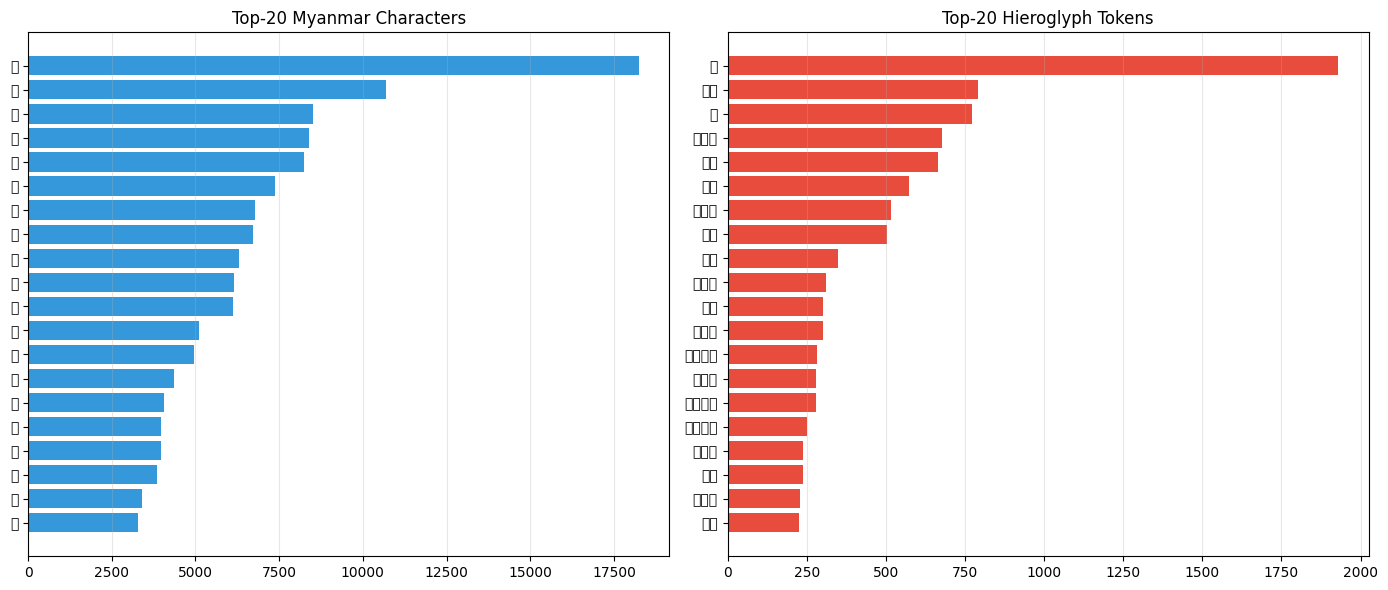

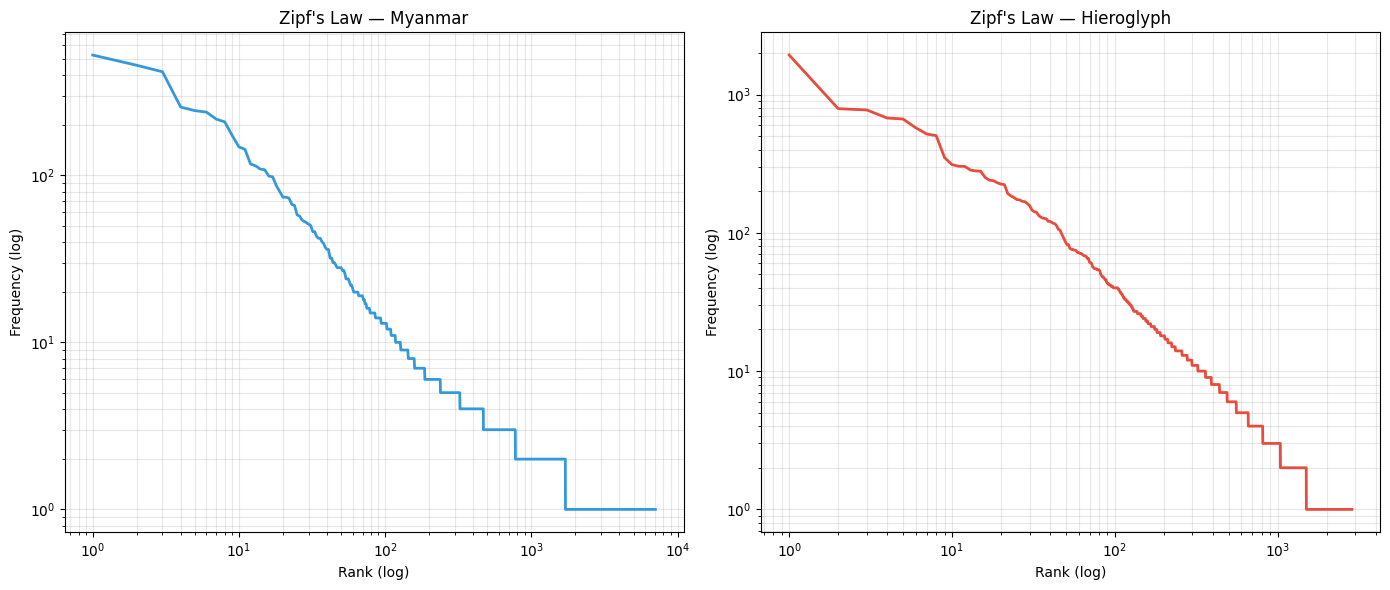


📄 SAMPLE PAIRS

[1] Myanmar:    မင်းက အေးဆေးတယ်
    Hieroglyph: 𓂨𓀀𓎡𓋴𓂝 𓏮𓀀𓐍𓂋

[2] Myanmar:    ရိုးသားမှုရှိတယ်
    Hieroglyph: 𓏏𓂝𓋴𓂝 𓈙𓆑𓎛𓏭𓂝𓋴𓂝

[3] Myanmar:    ကျွန်မ ရိုးသားနိုင်လား။
    Hieroglyph: 𓏭𓄿𓎛 𓆑 𓇋𓂝 𓊪𓐍𓎛𓂝𓈙𓈎

[4] Myanmar:    ဘယ်လို သက်သာမှုလဲ။
    Hieroglyph: 𓏏𓊪𓄿𓈎 𓄿 𓋴𓂝𓂋𓆑𓂝𓅱

[5] Myanmar:    ကျွန်မသွားခွင့်ပြုပါ။
    Hieroglyph: 𓄿𓂋𓂋𓐍𓏏 𓉔𓂝 𓈎𓐍 𓃀𓐍

📊 STATISTICAL SUMMARY
Split    Lang  Count  Avg_Chars  Max_Chars  Avg_Words  Max_Words
train Myanmar   8500       20.2         53        1.9          6
train   Hiero   8500       13.5         17        3.2          5
valid Myanmar   1000       19.7         44        1.9          5
valid   Hiero   1000       13.6         17        3.2          5
 test Myanmar    500       20.4         42        1.9          4
 test   Hiero    500       13.4         17        3.1          5

✅ Data visualization complete!


In [ ]:
# ============================================================
# STEP 4: DATA VISUALIZATION
# ============================================================
print("=" * 60)
print("STEP 4: DATA VISUALIZATION")
print("=" * 60)

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

def load_lines(path):
    with open(path, encoding='utf-8') as f:
        return [l.strip() for l in f if l.strip()]

splits = ['train', 'valid', 'test']
data = {s: {'my': load_lines(f'{s}.my'), 'hi': load_lines(f'{s}.hi')} for s in splits}

print("\n📊 Data loaded:")
for s in splits:
    print(f"  {s}: my={len(data[s]['my'])}, hi={len(data[s]['hi'])}")

# ---------- 1. Dataset size bar + pie ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sizes_my = [len(data[s]['my']) for s in splits]
sizes_hi = [len(data[s]['hi']) for s in splits]
x = np.arange(len(splits)); width = 0.35

axes[0].bar(x - width/2, sizes_my, width, label='Myanmar', color='#3498db')
axes[0].bar(x + width/2, sizes_hi, width, label='Hieroglyph', color='#e74c3c')
axes[0].set_xticks(x); axes[0].set_xticklabels(splits)
axes[0].set_ylabel('Line Count'); axes[0].set_title('Dataset Size per Split')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i, (v1, v2) in enumerate(zip(sizes_my, sizes_hi)):
    axes[0].text(i - width/2, v1 + 50, str(v1), ha='center', fontsize=9)
    axes[0].text(i + width/2, v2 + 50, str(v2), ha='center', fontsize=9)

total = sum(sizes_my)
axes[1].pie(sizes_my, labels=[f'{s}\n({n})' for s, n in zip(splits, sizes_my)],
            autopct='%1.1f%%', colors=['#2ecc71', '#f39c12', '#9b59b6'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title(f'Data Split Ratio (Total = {total})')
plt.tight_layout(); plt.show()

# ---------- 2. Sentence length histograms ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
my_lens = [len(s) for s in data['train']['my']]
hi_lens = [len(s) for s in data['train']['hi']]
my_words = [len(s.split()) for s in data['train']['my']]
hi_words = [len(s.split()) for s in data['train']['hi']]

axes[0,0].hist(my_lens, bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[0,0].axvline(np.mean(my_lens), color='red', linestyle='--', label=f'Mean: {np.mean(my_lens):.1f}')
axes[0,0].axvline(np.median(my_lens), color='green', linestyle='--', label=f'Median: {np.median(my_lens):.1f}')
axes[0,0].set_title('Myanmar Sentence Length (chars)'); axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

axes[0,1].hist(hi_lens, bins=50, color='#e74c3c', edgecolor='black', alpha=0.7)
axes[0,1].axvline(np.mean(hi_lens), color='red', linestyle='--', label=f'Mean: {np.mean(hi_lens):.1f}')
axes[0,1].axvline(np.median(hi_lens), color='green', linestyle='--', label=f'Median: {np.median(hi_lens):.1f}')
axes[0,1].set_title('Hieroglyph Sentence Length (chars)'); axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

axes[1,0].hist(my_words, bins=30, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[1,0].axvline(np.mean(my_words), color='red', linestyle='--', label=f'Mean: {np.mean(my_words):.1f}')
axes[1,0].set_title('Myanmar Sentence Length (words)'); axes[1,0].legend(); axes[1,0].grid(alpha=0.3)

axes[1,1].hist(hi_words, bins=30, color='#9b59b6', edgecolor='black', alpha=0.7)
axes[1,1].axvline(np.mean(hi_words), color='red', linestyle='--', label=f'Mean: {np.mean(hi_words):.1f}')
axes[1,1].set_title('Hieroglyph Sentence Length (words)'); axes[1,1].legend(); axes[1,1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------- 3. Length correlation ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(my_lens, hi_lens, alpha=0.3, s=10, color='#3498db')
axes[0].set_xlabel('Myanmar Length (chars)'); axes[0].set_ylabel('Hieroglyph Length (chars)')
axes[0].set_title('Myanmar vs Hieroglyph Length'); axes[0].grid(alpha=0.3)
corr = np.corrcoef(my_lens, hi_lens)[0, 1]
axes[0].text(0.05, 0.95, f'Pearson r = {corr:.3f}', transform=axes[0].transAxes,
             fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

axes[1].scatter(my_words, hi_words, alpha=0.3, s=10, color='#e74c3c')
axes[1].set_xlabel('Myanmar Word Count'); axes[1].set_ylabel('Hieroglyph Word Count')
axes[1].set_title('Myanmar vs Hieroglyph Word Count'); axes[1].grid(alpha=0.3)
corr_w = np.corrcoef(my_words, hi_words)[0, 1]
axes[1].text(0.05, 0.95, f'Pearson r = {corr_w:.3f}', transform=axes[1].transAxes,
             fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
plt.tight_layout(); plt.show()

# ---------- 4. Vocabulary ----------
print("\n" + "=" * 60)
print("📚 VOCABULARY ANALYSIS")
print("=" * 60)

my_text = ' '.join(data['train']['my'])
my_char_freq = Counter(my_text.replace(' ', ''))
my_word_freq = Counter(my_text.split())
hi_text = ' '.join(data['train']['hi'])
hi_token_freq = Counter(hi_text.split())

print(f"\n[Myanmar]")
print(f"  Total chars:  {sum(my_char_freq.values()):,}")
print(f"  Unique chars: {len(my_char_freq):,}")
print(f"  Total words:  {sum(my_word_freq.values()):,}")
print(f"  Unique words: {len(my_word_freq):,}")
print(f"\n[Hieroglyph]")
print(f"  Total tokens:  {sum(hi_token_freq.values()):,}")
print(f"  Unique tokens: {len(hi_token_freq):,}")

# ---------- 5. Top-20 ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_my = my_char_freq.most_common(20)
chars, counts = zip(*top_my)
display_chars = ['SPACE' if c.isspace() else c for c in chars]
axes[0].barh(range(len(chars)), counts, color='#3498db')
axes[0].set_yticks(range(len(chars))); axes[0].set_yticklabels(display_chars, fontsize=10)
axes[0].invert_yaxis(); axes[0].set_title('Top-20 Myanmar Characters'); axes[0].grid(axis='x', alpha=0.3)

top_hi = hi_token_freq.most_common(20)
tokens, counts_hi = zip(*top_hi)
axes[1].barh(range(len(tokens)), counts_hi, color='#e74c3c')
axes[1].set_yticks(range(len(tokens))); axes[1].set_yticklabels(tokens, fontsize=10)
axes[1].invert_yaxis(); axes[1].set_title('Top-20 Hieroglyph Tokens'); axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

# ---------- 6. Zipf's Law ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
my_freqs = sorted(my_word_freq.values(), reverse=True)
axes[0].loglog(np.arange(1, len(my_freqs)+1), my_freqs, color='#3498db', linewidth=2)
axes[0].set_xlabel('Rank (log)'); axes[0].set_ylabel('Frequency (log)')
axes[0].set_title("Zipf's Law — Myanmar"); axes[0].grid(alpha=0.3, which='both')

hi_freqs = sorted(hi_token_freq.values(), reverse=True)
axes[1].loglog(np.arange(1, len(hi_freqs)+1), hi_freqs, color='#e74c3c', linewidth=2)
axes[1].set_xlabel('Rank (log)'); axes[1].set_ylabel('Frequency (log)')
axes[1].set_title("Zipf's Law — Hieroglyph"); axes[1].grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

# ---------- 7. Sample pairs ----------
print("\n" + "=" * 60)
print("📄 SAMPLE PAIRS")
print("=" * 60)
for i in range(min(5, len(data['train']['my']))):
    print(f"\n[{i+1}] Myanmar:    {data['train']['my'][i]}")
    print(f"    Hieroglyph: {data['train']['hi'][i]}")

# ---------- 8. Statistics ----------
print("\n" + "=" * 60)
print("📊 STATISTICAL SUMMARY")
print("=" * 60)
summary = []
for s in splits:
    for lang in ['my', 'hi']:
        lengths = [len(x) for x in data[s][lang]]
        words = [len(x.split()) for x in data[s][lang]]
        summary.append({
            'Split': s, 'Lang': 'Myanmar' if lang == 'my' else 'Hiero',
            'Count': len(data[s][lang]),
            'Avg_Chars': round(np.mean(lengths), 1),
            'Max_Chars': int(np.max(lengths)),
            'Avg_Words': round(np.mean(words), 1),
            'Max_Words': int(np.max(words)),
        })
print(pd.DataFrame(summary).to_string(index=False))
print("\n✅ Data visualization complete!")

## 5. Preprocessing / ၅။ ဒေတာ ပြင်ဆင်ခြင်း

**English:**  
**SentencePiece** is a subword tokenizer. It splits sentences into subword units, allowing NMT to handle rare words and morphological variation.

**မြန်မာ:**  
**SentencePiece** သည် စာကြောင်းများကို **subword** (စကားလုံးအစိတ်အပိုင်း) များအဖြစ် ခွဲပေးသော tokenizer ဖြစ်ပါသည်။

### Steps / အဆင့်များ

1. Combine train + valid + test
2. Train SentencePiece for both languages
3. Encode the data with `<s>` and `</s>` tokens

### Key Parameters / အရေးကြီး Parameters

| Parameter | Value | Meaning |
|-----------|-------|---------|
| vocab_size | 8000 | Number of subwords |
| character_coverage | 1.0 | Full character coverage |
| model_type | unigram | Unigram algorithm |
| unk_id, bos_id, eos_id | 0, 1, 2 | Special tokens (needed by Marian) |

**Note**: We use the **Python API** because `spm_train` command-line tool is not available in Colab.

In [ ]:
# ============================================================
# STEP 5: SENTENCEPIECE PREPROCESSING (Python API)
# ============================================================
print("=" * 60)
print("STEP 5: SENTENCEPIECE PREPROCESSING")
print("=" * 60)

import os
import sentencepiece as spm

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

# -------- Combine --------
print("\n🔄 Combining data...")
!cat train.my valid.my test.my > all.my
!cat train.hi valid.hi test.hi > all.hi
print(f"  all.my: {os.path.getsize('all.my')} B")
print(f"  all.hi: {os.path.getsize('all.hi')} B")

# -------- Myanmar SentencePiece --------
print("\n🔨 Training Myanmar SentencePiece...")
spm.SentencePieceTrainer.train(
    input='all.my', model_prefix='my_spm',
    vocab_size=8000, character_coverage=1.0,
    model_type='unigram', num_threads=4,
    unk_id=0, bos_id=1, eos_id=2, pad_id=3,
    unk_piece='<unk>', bos_piece='<s>', eos_piece='</s>', pad_piece='<pad>',
    hard_vocab_limit=False
)
print(f"  ✅ my_spm.model ({os.path.getsize('my_spm.model')} B)")

# -------- Hieroglyph SentencePiece --------
print("\n🔨 Training Hieroglyph SentencePiece...")
spm.SentencePieceTrainer.train(
    input='all.hi', model_prefix='hi_spm',
    vocab_size=8000, character_coverage=1.0,
    model_type='unigram', num_threads=4,
    unk_id=0, bos_id=1, eos_id=2, pad_id=3,
    unk_piece='<unk>', bos_piece='<s>', eos_piece='</s>', pad_piece='<pad>',
    hard_vocab_limit=False
)
print(f"  ✅ hi_spm.model ({os.path.getsize('hi_spm.model')} B)")

# -------- Encode --------
print("\n🔄 Encoding data...")
my_sp = spm.SentencePieceProcessor(model_file='my_spm.model')
hi_sp = spm.SentencePieceProcessor(model_file='hi_spm.model')

def encode_file(infile, outfile, sp):
    with open(infile, encoding='utf-8') as f_in, \
         open(outfile, 'w', encoding='utf-8') as f_out:
        for line in f_in:
            line = line.strip()
            if not line:
                continue
            pieces = sp.encode(line, out_type=str)
            pieces = ['<s>'] + pieces + ['</s>']
            f_out.write(' '.join(pieces) + '\n')

for split in ['train', 'valid', 'test']:
    encode_file(f'{split}.my', f'{split}.my.sp', my_sp)
    encode_file(f'{split}.hi', f'{split}.hi.sp', hi_sp)
    print(f"  ✅ {split}: my={os.path.getsize(f'{split}.my.sp')}B, hi={os.path.getsize(f'{split}.hi.sp')}B")

# -------- Verify --------
print("\n📁 Final files:")
!ls -la *.model *.vocab *.sp
print("\n📄 Sample (train.my.sp):")
!head -2 train.my.sp
print("\n✅ Preprocessing complete!")

STEP 5: SENTENCEPIECE PREPROCESSING

🔄 Combining data...
  all.my: 590862 B
  all.hi: 485942 B

🔨 Training Myanmar SentencePiece...
  ✅ my_spm.model (473255 B)

🔨 Training Hieroglyph SentencePiece...
  ✅ hi_spm.model (325942 B)

🔄 Encoding data...
  ✅ train: my=635150B, hi=571286B
  ✅ valid: my=73408B, hi=67539B
  ✅ test: my=37772B, hi=33421B

📁 Final files:
-rw-r--r-- 1 root root  76177 Oct 10 16:50 hi_spm.marian.vocab
-rw------- 1 root root 325942 Oct 10 16:52 hi_spm.model
-rw------- 1 root root  88353 Oct 10 16:52 hi_spm.vocab
-rw-r--r-- 1 root root 212435 Oct 10 16:50 my_spm.marian.vocab
-rw------- 1 root root 473255 Oct 10 16:52 my_spm.model
-rw------- 1 root root 238976 Oct 10 16:52 my_spm.vocab
-rw------- 1 root root  33421 Oct 10 16:52 test.hi.sp
-rw------- 1 root root  37772 Oct 10 16:52 test.my.sp
-rw------- 1 root root 571286 Oct 10 16:52 train.hi.sp
-rw------- 1 root root 635150 Oct 10 16:52 train.my.sp
-rw------- 1 root root  67539 Oct 10 16:52 valid.hi.sp
-rw------- 1 roo

## 6. Config Files / ၆။ Config Files ဖန်တီးခြင်း

**English:**  
We create 4 YAML configs — one for each architecture and direction.

**မြန်မာ:**  
Architecture နှင့် ဦးတည်ချက် တစ်ခုစီအတွက် YAML config ဖိုင် ၄ ခု ဖန်တီးပါမည်။

| Config File | Direction |
|-------------|-----------|
| `config_transformer.yml` | Transformer (Myanmar → Hiero) |
| `config_s2s.yml` | Seq2Seq (Myanmar → Hiero) |
| `config_transformer_reverse.yml` | Transformer (Hiero → Myanmar) |
| `config_s2s_reverse.yml` | Seq2Seq (Hiero → Myanmar) |

### Key Parameters / အဓိက Parameters

**Transformer**: `dim-emb: 256`, `enc-depth: 3`, `dec-depth: 3`, `transformer-heads: 4`  
**Seq2Seq**: `dim-emb: 256`, `dim-rnn: 512`, `enc-depth: 2`, `dec-depth: 2`  
**Training**: `learn-rate: 0.0003`, `mini-batch: 32`, `early-stopping: 5`

**Note**: We do **NOT** include a `vocabs` section — Marian will auto-build vocabs from the encoded data.

In [ ]:
# ============================================================
# STEP 6: CREATE CONFIG FILES
# ============================================================
print("=" * 60)
print("STEP 6: CREATE CONFIG FILES")
print("=" * 60)

import os
DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

# Clean old configs
!rm -f config_*.yml

# ---- Common config template ----
TRANSFORMER_MY_HI = """train-sets:
  - train.my.sp
  - train.hi.sp
valid-sets:
  - valid.my.sp
  - valid.hi.sp
model: model_transformer_my_hi.npz
type: transformer
dim-emb: 256
enc-depth: 3
dec-depth: 3
transformer-heads: 4
transformer-dropout: 0.1
learn-rate: 0.0003
lr-warmup: 2000
lr-decay-inv-sqrt: 2000
clip-norm: 5
label-smoothing: 0.1
valid-metrics:
  - cross-entropy
early-stopping: 5
valid-freq: 500
save-freq: 500
optimizer: adam
optimizer-params: [0.9, 0.98, 1e-09]
mini-batch: 32
workspace: 2000
beam-size: 4
"""

S2S_MY_HI = """train-sets:
  - train.my.sp
  - train.hi.sp
valid-sets:
  - valid.my.sp
  - valid.hi.sp
model: model_s2s_my_hi.npz
type: s2s
dim-emb: 256
dim-rnn: 512
enc-depth: 2
dec-depth: 2
learn-rate: 0.0003
lr-warmup: 2000
lr-decay-inv-sqrt: 2000
clip-norm: 5
dropout-rnn: 0.2
dropout-src: 0.1
dropout-trg: 0.1
valid-metrics:
  - cross-entropy
early-stopping: 5
valid-freq: 500
save-freq: 500
optimizer: adam
optimizer-params: [0.9, 0.98, 1e-09]
mini-batch: 32
workspace: 2000
beam-size: 4
"""

TRANSFORMER_HI_MY = """train-sets:
  - train.hi.sp
  - train.my.sp
valid-sets:
  - valid.hi.sp
  - valid.my.sp
model: model_transformer_hi_my.npz
type: transformer
dim-emb: 256
enc-depth: 3
dec-depth: 3
transformer-heads: 4
transformer-dropout: 0.1
learn-rate: 0.0003
lr-warmup: 2000
lr-decay-inv-sqrt: 2000
clip-norm: 5
label-smoothing: 0.1
valid-metrics:
  - cross-entropy
early-stopping: 5
valid-freq: 500
save-freq: 500
optimizer: adam
optimizer-params: [0.9, 0.98, 1e-09]
mini-batch: 32
workspace: 2000
beam-size: 4
"""

S2S_HI_MY = """train-sets:
  - train.hi.sp
  - train.my.sp
valid-sets:
  - valid.hi.sp
  - valid.my.sp
model: model_s2s_hi_my.npz
type: s2s
dim-emb: 256
dim-rnn: 512
enc-depth: 2
dec-depth: 2
learn-rate: 0.0003
lr-warmup: 2000
lr-decay-inv-sqrt: 2000
clip-norm: 5
dropout-rnn: 0.2
dropout-src: 0.1
dropout-trg: 0.1
valid-metrics:
  - cross-entropy
early-stopping: 5
valid-freq: 500
save-freq: 500
optimizer: adam
optimizer-params: [0.9, 0.98, 1e-09]
mini-batch: 32
workspace: 2000
beam-size: 4
"""

# ---- Write config files ----
with open('config_transformer.yml', 'w') as f:
    f.write(TRANSFORMER_MY_HI)

with open('config_s2s.yml', 'w') as f:
    f.write(S2S_MY_HI)

with open('config_transformer_reverse.yml', 'w') as f:
    f.write(TRANSFORMER_HI_MY)

with open('config_s2s_reverse.yml', 'w') as f:
    f.write(S2S_HI_MY)

print("✅ All 4 config files created")
!ls -la config_*.yml

STEP 6: CREATE CONFIG FILES
✅ All 4 config files created
-rw-r--r-- 1 root root 479 Oct 10 16:52 config_s2s_reverse.yml
-rw-r--r-- 1 root root 479 Oct 10 16:52 config_s2s.yml
-rw-r--r-- 1 root root 498 Oct 10 16:52 config_transformer_reverse.yml
-rw-r--r-- 1 root root 498 Oct 10 16:52 config_transformer.yml


In [ ]:
# Check config files
import os
DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("📁 CONFIG FILES CHECK")
print("=" * 60)

for f in ['config_transformer.yml', 'config_s2s.yml',
          'config_transformer_reverse.yml', 'config_s2s_reverse.yml']:
    if os.path.exists(f):
        size = os.path.getsize(f)
        with open(f) as fh:
            lines = len(fh.readlines())
        print(f"  ✅ {f} ({size} B, {lines} lines)")
    else:
        print(f"  ❌ {f} MISSING")

print("\n📄 config_transformer.yml content:")
!cat config_transformer.yml

📁 CONFIG FILES CHECK
  ✅ config_transformer.yml (498 B, 28 lines)
  ✅ config_s2s.yml (479 B, 29 lines)
  ✅ config_transformer_reverse.yml (498 B, 28 lines)
  ✅ config_s2s_reverse.yml (479 B, 29 lines)

📄 config_transformer.yml content:
train-sets:
  - train.my.sp
  - train.hi.sp
valid-sets:
  - valid.my.sp
  - valid.hi.sp
model: model_transformer_my_hi.npz
type: transformer
dim-emb: 256
enc-depth: 3
dec-depth: 3
transformer-heads: 4
transformer-dropout: 0.1
learn-rate: 0.0003
lr-warmup: 2000
lr-decay-inv-sqrt: 2000
clip-norm: 5
label-smoothing: 0.1
valid-metrics:
  - cross-entropy
early-stopping: 5
valid-freq: 500
save-freq: 500
optimizer: adam
optimizer-params: [0.9, 0.98, 1e-09]
mini-batch: 32
workspace: 2000
beam-size: 4


## 7. Training / ၇။ မော်ဒယ် လေ့ကျင့်ခြင်း

**English:**  
We train 4 models — 2 architectures (Transformer, Seq2Seq) × 2 directions (Myanmar→Hiero, Hiero→Myanmar).

**မြန်မာ:**  
မော်ဒယ် ၄ ခု လေ့ကျင့်ပါမည် — Architecture ၂ မျိုး (Transformer, Seq2Seq) × ဦးတည်ချက် ၂ မျိုး (မြန်မာ→ဟိအဲရိုး, ဟိအဲရိုး→မြန်မာ)။

| # | Model | Direction |
|---|-------|-----------|
| 1 | Transformer | Myanmar → Hiero |
| 2 | Seq2Seq | Myanmar → Hiero |
| 3 | Transformer | Hiero → Myanmar |
| 4 | Seq2Seq | Hiero → Myanmar |

### Training Time / လေ့ကျင့်ချိန်

- **Transformer**: ~30–60 min (CPU) / ~15 min (GPU)
- **Seq2Seq**: ~45–90 min (CPU) / ~30 min (GPU)

### Important Notes / သတိထားရမည့်အချက်

- Colab has a **90-minute idle limit** — keep the tab open
- Model file (`.npz`) creation means success
- **Total: 3–5 hours (CPU) / 1–1.5 hours (GPU)**

**မြန်မာ**: Colab မှာ **၉၀ မိနစ် idle** ဖြစ်ရင် disconnect ဖြစ်တယ် — tab ကို ဖွင့်ထားပါ။ **Model file (`.npz`) ဖန်တီးပြီးမှ** အောင်မြင်သည်ဟု သတ်မှတ်ပါ။

In [ ]:
# ============================================================
# VERIFY PREREQUISITES BEFORE TRAINING
# ============================================================
import os

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("🔍 PREREQUISITES CHECK")
print("=" * 60)

# 1. Marian binary
MARIAN_BIN = '/content/marian/build/marian'
print(f"\n1. Marian binary:")
if os.path.exists(MARIAN_BIN):
    print(f"   ✅ {MARIAN_BIN}")
else:
    print(f"   ❌ NOT FOUND — compile Marian first!")

# 2. Data files
print(f"\n2. Data files:")
data_files = ['train.my.sp', 'train.hi.sp', 'valid.my.sp', 'valid.hi.sp',
              'test.my.sp', 'test.hi.sp']
all_data_ok = True
for f in data_files:
    if os.path.exists(f) and os.path.getsize(f) > 0:
        print(f"   ✅ {f} ({os.path.getsize(f)} B)")
    else:
        print(f"   ❌ {f} MISSING or EMPTY")
        all_data_ok = False

# 3. Config files
print(f"\n3. Config files:")
config_files = ['config_transformer.yml', 'config_s2s.yml',
                'config_transformer_reverse.yml', 'config_s2s_reverse.yml']
all_cfg_ok = True
for f in config_files:
    if os.path.exists(f):
        print(f"   ✅ {f} ({os.path.getsize(f)} B)")
    else:
        print(f"   ❌ {f} MISSING")
        all_cfg_ok = False

# 4. SentencePiece models
print(f"\n4. SentencePiece models:")
for f in ['my_spm.model', 'hi_spm.model']:
    if os.path.exists(f):
        print(f"   ✅ {f} ({os.path.getsize(f)} B)")
    else:
        print(f"   ❌ {f} MISSING")

# Summary
print("\n" + "=" * 60)
print("📋 SUMMARY")
print("=" * 60)
if os.path.exists(MARIAN_BIN) and all_data_ok and all_cfg_ok:
    print("✅ ALL PREREQUISITES MET — Ready for training!")
else:
    print("❌ Some prerequisites missing. Fix them first.")

🔍 PREREQUISITES CHECK

1. Marian binary:
   ✅ /content/marian/build/marian

2. Data files:
   ✅ train.my.sp (635150 B)
   ✅ train.hi.sp (571286 B)
   ✅ valid.my.sp (73408 B)
   ✅ valid.hi.sp (67539 B)
   ✅ test.my.sp (37772 B)
   ✅ test.hi.sp (33421 B)

3. Config files:
   ✅ config_transformer.yml (498 B)
   ✅ config_s2s.yml (479 B)
   ✅ config_transformer_reverse.yml (498 B)
   ✅ config_s2s_reverse.yml (479 B)

4. SentencePiece models:
   ✅ my_spm.model (473255 B)
   ✅ hi_spm.model (325942 B)

📋 SUMMARY
✅ ALL PREREQUISITES MET — Ready for training!


In [ ]:
# ============================================================
# MOUNT GOOGLE DRIVE (Save models to Drive)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

# Create folder for models
import os
DRIVE_DIR = '/content/drive/MyDrive/nmt_models'
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f"✅ Drive mounted: {DRIVE_DIR}")

Mounted at /content/drive
✅ Drive mounted: /content/drive/MyDrive/nmt_models


In [ ]:
# ============================================================
# STEP 7.1: TRAIN TRANSFORMER (Myanmar → Hiero)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

print("=" * 60)
print("🚀 TRAINING: Transformer (Myanmar → Hiero)")
print("=" * 60)

# Check prerequisites
if not os.path.exists(MARIAN_BIN):
    raise FileNotFoundError(f"❌ Marian not found: {MARIAN_BIN}")
if not os.path.exists('config_transformer.yml'):
    raise FileNotFoundError("❌ config_transformer.yml not found!")

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_transformer.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Training time: {elapsed:.1f} minutes")
print(f"Return code: {result.returncode}")

# Save training log
with open('train_tf_my_hi.log', 'w') as f:
    f.write(result.stdout)
    f.write("\n\n=== STDERR ===\n\n")
    f.write(result.stderr)

# Show last part of output
print("\n--- Last 500 chars of STDOUT ---")
print(result.stdout[-500:])

if result.returncode == 0 and os.path.exists('model_transformer_my_hi.npz'):
    size_mb = os.path.getsize('model_transformer_my_hi.npz') / 1e6
    print(f"\n✅ SUCCESS: model_transformer_my_hi.npz ({size_mb:.1f} MB)")
else:
    print("\n❌ FAILED!")
    print("--- Last 1000 chars of STDERR ---")
    print(result.stderr[-1000:])

🚀 TRAINING: Transformer (Myanmar → Hiero)

⏱️  Training time: 70.0 minutes
Return code: 0

--- Last 500 chars of STDOUT ---


✅ SUCCESS: model_transformer_my_hi.npz (46.3 MB)


In [ ]:
# What's currently in /content?
import os

print("=" * 60)
print("📁 /content/ CONTENTS")
print("=" * 60)

for item in os.listdir('/content'):
    path = os.path.join('/content', item)
    if os.path.isdir(path):
        print(f"  📁 {item}/")
    else:
        size = os.path.getsize(path)
        print(f"  📄 {item} ({size} B)")

# Check specifically for what we need
print("\n" + "=" * 60)
print("🔍 REQUIRED ITEMS CHECK")
print("=" * 60)

checks = {
    'Marian binary': '/content/marian/build/marian',
    'Marian source': '/content/marian',
    'AIE-F-B2 repo': '/content/AIE-F-B2',
    'Data folder': '/content/AIE-F-B2/assignment/assignment-6/myhi_data',
}

for name, path in checks.items():
    if os.path.exists(path):
        print(f"  ✅ {name}: {path}")
    else:
        print(f"  ❌ {name}: {path} — MISSING")

📁 /content/ CONTENTS
  📁 .config/
  📁 marian/
  📁 AIE-F-B2/
  📁 drive/
  📁 sample_data/

🔍 REQUIRED ITEMS CHECK
  ✅ Marian binary: /content/marian/build/marian
  ✅ Marian source: /content/marian
  ✅ AIE-F-B2 repo: /content/AIE-F-B2
  ✅ Data folder: /content/AIE-F-B2/assignment/assignment-6/myhi_data


In [ ]:
# ============================================================
# STEP 7.2: TRAIN SEQ2SEQ (Myanmar → Hiero)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

print("=" * 60)
print("🚀 TRAINING: Seq2Seq (Myanmar → Hiero)")
print("=" * 60)

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_s2s.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Training time: {elapsed:.1f} minutes")
print(f"Return code: {result.returncode}")

with open('train_s2s_my_hi.log', 'w') as f:
    f.write(result.stdout + "\n\n=== STDERR ===\n\n" + result.stderr)

if result.returncode == 0 and os.path.exists('model_s2s_my_hi.npz'):
    size_mb = os.path.getsize('model_s2s_my_hi.npz') / 1e6
    print(f"✅ SUCCESS: model_s2s_my_hi.npz ({size_mb:.1f} MB)")
else:
    print("❌ FAILED!")
    print(result.stderr[-1000:])

🚀 TRAINING: Seq2Seq (Myanmar → Hiero)

⏱️  Training time: 172.2 minutes
Return code: 0
✅ SUCCESS: model_s2s_my_hi.npz (64.3 MB)


In [ ]:
# Check current state
import os

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'

if not os.path.exists(DATA_DIR):
    print(f"❌ Data folder missing: {DATA_DIR}")
    print("→ Colab session restarted. Need full re-setup.")
else:
    os.chdir(DATA_DIR)
    print(f"✅ Data folder: {DATA_DIR}\n")

    print("📁 Files present:")
    !ls -la

    print("\n🔍 Required files check:")
    required = [
        'my_spm.model', 'hi_spm.model',
        'train.my.sp', 'train.hi.sp', 'valid.my.sp', 'valid.hi.sp',
        'config_transformer.yml', 'config_s2s.yml',
        'config_transformer_reverse.yml', 'config_s2s_reverse.yml',
    ]
    for f in required:
        size = os.path.getsize(f) if os.path.exists(f) else 0
        print(f"  {'✅' if size > 0 else '❌'} {f} ({size} B)")

✅ Data folder: /content/AIE-F-B2/assignment/assignment-6/myhi_data

📁 Files present:
total 1100
drwxr-xr-x 2 root root   4096 Oct 10 01:28 .
drwxr-xr-x 4 root root   4096 Oct 10 01:19 ..
-rw-r--r-- 1 root root    479 Oct 10 01:28 config_s2s_reverse.yml
-rw-r--r-- 1 root root    479 Oct 10 01:28 config_s2s.yml
-rw-r--r-- 1 root root    498 Oct 10 01:28 config_transformer_reverse.yml
-rw-r--r-- 1 root root    498 Oct 10 01:28 config_transformer.yml
-rw-r--r-- 1 root root  24117 Oct 10 01:19 test.hi
-rw-r--r-- 1 root root  29994 Oct 10 01:19 test.my
-rw-r--r-- 1 root root 412919 Oct 10 01:19 train.hi
-rw-r--r-- 1 root root 502978 Oct 10 01:19 train.my
-rw-r--r-- 1 root root  13855 Oct 10 01:29 train_tf_hi_my.log
-rw-r--r-- 1 root root  48906 Oct 10 01:19 valid.hi
-rw-r--r-- 1 root root  57890 Oct 10 01:19 valid.my

🔍 Required files check:
  ❌ my_spm.model (0 B)
  ❌ hi_spm.model (0 B)
  ❌ train.my.sp (0 B)
  ❌ train.hi.sp (0 B)
  ❌ valid.my.sp (0 B)
  ❌ valid.hi.sp (0 B)
  ✅ config_transfo

In [ ]:
# ============================================================
# SENTENCEPIECE PREPROCESSING (Re-run)
# ============================================================
print("=" * 60)
print("SENTENCEPIECE PREPROCESSING")
print("=" * 60)

import os
import sentencepiece as spm

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
print(f"✅ Working in: {DATA_DIR}\n")

# ---------- Step 1: Combine data ----------
print("🔄 Step 1: Combining data...")
!cat train.my valid.my test.my > all.my
!cat train.hi valid.hi test.hi > all.hi
print(f"   all.my: {os.path.getsize('all.my')} B")
print(f"   all.hi: {os.path.getsize('all.hi')} B")

# ---------- Step 2: Myanmar SentencePiece ----------
print("\n🔨 Step 2: Training Myanmar SentencePiece...")
spm.SentencePieceTrainer.train(
    input='all.my',
    model_prefix='my_spm',
    vocab_size=8000,
    character_coverage=1.0,
    model_type='unigram',
    num_threads=4,
    unk_id=0, bos_id=1, eos_id=2, pad_id=3,
    unk_piece='<unk>', bos_piece='<s>', eos_piece='</s>', pad_piece='<pad>',
    hard_vocab_limit=False
)
print(f"   ✅ my_spm.model: {os.path.getsize('my_spm.model')} B")
print(f"   ✅ my_spm.vocab: {os.path.getsize('my_spm.vocab')} B")

# ---------- Step 3: Hieroglyph SentencePiece ----------
print("\n🔨 Step 3: Training Hieroglyph SentencePiece...")
spm.SentencePieceTrainer.train(
    input='all.hi',
    model_prefix='hi_spm',
    vocab_size=8000,
    character_coverage=1.0,
    model_type='unigram',
    num_threads=4,
    unk_id=0, bos_id=1, eos_id=2, pad_id=3,
    unk_piece='<unk>', bos_piece='<s>', eos_piece='</s>', pad_piece='<pad>',
    hard_vocab_limit=False
)
print(f"   ✅ hi_spm.model: {os.path.getsize('hi_spm.model')} B")
print(f"   ✅ hi_spm.vocab: {os.path.getsize('hi_spm.vocab')} B")

# ---------- Step 4: Encode data ----------
print("\n🔄 Step 4: Encoding data...")
my_sp = spm.SentencePieceProcessor(model_file='my_spm.model')
hi_sp = spm.SentencePieceProcessor(model_file='hi_spm.model')

def encode_file(infile, outfile, sp):
    with open(infile, encoding='utf-8') as f_in, \
         open(outfile, 'w', encoding='utf-8') as f_out:
        for line in f_in:
            line = line.strip()
            if not line:
                continue
            pieces = ['<s>'] + sp.encode(line, out_type=str) + ['</s>']
            f_out.write(' '.join(pieces) + '\n')

for split in ['train', 'valid', 'test']:
    encode_file(f'{split}.my', f'{split}.my.sp', my_sp)
    encode_file(f'{split}.hi', f'{split}.hi.sp', hi_sp)
    my_size = os.path.getsize(f'{split}.my.sp')
    hi_size = os.path.getsize(f'{split}.hi.sp')
    print(f"   ✅ {split}: my={my_size}B, hi={hi_size}B")

# ---------- Step 5: Verify ----------
print("\n" + "=" * 60)
print("📁 FINAL FILES")
print("=" * 60)
!ls -la *.model *.vocab *.sp

print("\n📄 Sample (train.my.sp):")
!head -2 train.my.sp
print("\n📄 Sample (train.hi.sp):")
!head -2 train.hi.sp

print("\n✅ Preprocessing complete!")

SENTENCEPIECE PREPROCESSING
✅ Working in: /content/AIE-F-B2/assignment/assignment-6/myhi_data

🔄 Step 1: Combining data...
   all.my: 590862 B
   all.hi: 485942 B

🔨 Step 2: Training Myanmar SentencePiece...
   ✅ my_spm.model: 473255 B
   ✅ my_spm.vocab: 238976 B

🔨 Step 3: Training Hieroglyph SentencePiece...
   ✅ hi_spm.model: 325942 B
   ✅ hi_spm.vocab: 88353 B

🔄 Step 4: Encoding data...
   ✅ train: my=635150B, hi=571286B
   ✅ valid: my=73408B, hi=67539B
   ✅ test: my=37772B, hi=33421B

📁 FINAL FILES
-rw-r--r-- 1 root root 325942 Oct 10 01:31 hi_spm.model
-rw-r--r-- 1 root root  88353 Oct 10 01:31 hi_spm.vocab
-rw-r--r-- 1 root root 473255 Oct 10 01:31 my_spm.model
-rw-r--r-- 1 root root 238976 Oct 10 01:31 my_spm.vocab
-rw-r--r-- 1 root root  33421 Oct 10 01:31 test.hi.sp
-rw-r--r-- 1 root root  37772 Oct 10 01:31 test.my.sp
-rw-r--r-- 1 root root 571286 Oct 10 01:31 train.hi.sp
-rw-r--r-- 1 root root 635150 Oct 10 01:31 train.my.sp
-rw-r--r-- 1 root root  67539 Oct 10 01:31 valid

In [ ]:
# ============================================================
# STEP 7.3: TRAIN TRANSFORMER (Hiero → Myanmar)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

print("=" * 60)
print("🚀 TRAINING: Transformer (Hiero → Myanmar)")
print("=" * 60)

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_transformer_reverse.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Training time: {elapsed:.1f} minutes")
print(f"Return code: {result.returncode}")

with open('train_tf_hi_my.log', 'w') as f:
    f.write(result.stdout + "\n\n=== STDERR ===\n\n" + result.stderr)

if result.returncode == 0 and os.path.exists('model_transformer_hi_my.npz'):
    size_mb = os.path.getsize('model_transformer_hi_my.npz') / 1e6
    print(f"✅ SUCCESS: model_transformer_hi_my.npz ({size_mb:.1f} MB)")
else:
    print("❌ FAILED!")
    print(result.stderr[-1500:])

🚀 TRAINING: Transformer (Hiero → Myanmar)

⏱️  Training time: 65.7 minutes
Return code: 0
✅ SUCCESS: model_transformer_hi_my.npz (49.7 MB)


In [ ]:
# ============================================================
# STEP 7.4: TRAIN SEQ2SEQ (Hiero → Myanmar)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

print("=" * 60)
print("🚀 TRAINING: Seq2Seq (Hiero → Myanmar)")
print("=" * 60)

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_s2s_reverse.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Training time: {elapsed:.1f} minutes")
print(f"Return code: {result.returncode}")

with open('train_s2s_hi_my.log', 'w') as f:
    f.write(result.stdout + "\n\n=== STDERR ===\n\n" + result.stderr)

if result.returncode == 0 and os.path.exists('model_s2s_hi_my.npz'):
    size_mb = os.path.getsize('model_s2s_hi_my.npz') / 1e6
    print(f"✅ SUCCESS: model_s2s_hi_my.npz ({size_mb:.1f} MB)")
else:
    print("❌ FAILED!")
    print(result.stderr[-1500:])

# All models
print("\n" + "=" * 60)
print("📁 ALL MODELS")
print("=" * 60)
!ls -la *.npz

🚀 TRAINING: Seq2Seq (Hiero → Myanmar)

⏱️  Training time: 311.3 minutes
Return code: 0
✅ SUCCESS: model_s2s_hi_my.npz (67.7 MB)

📁 ALL MODELS
-rw-r--r-- 1 root root  67669936 Oct 10 05:13 model_s2s_hi_my.iter10000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 02:56 model_s2s_hi_my.iter1000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:20 model_s2s_hi_my.iter10500.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:28 model_s2s_hi_my.iter11000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:36 model_s2s_hi_my.iter11500.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:43 model_s2s_hi_my.iter12000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:51 model_s2s_hi_my.iter12500.npz
-rw-r--r-- 1 root root  67669936 Oct 10 05:58 model_s2s_hi_my.iter13000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 06:06 model_s2s_hi_my.iter13500.npz
-rw-r--r-- 1 root root  67669936 Oct 10 06:14 model_s2s_hi_my.iter14000.npz
-rw-r--r-- 1 root root  67669936 Oct 10 06:21 model_s2s_hi_my.iter14500.npz
-rw-r--r-- 1 root root 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, shutil

DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
os.makedirs(DRIVE_DIR, exist_ok=True)

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'

# Save all models + configs + vocab
for f in os.listdir(DATA_DIR):
    if f.endswith(('.sp', '.model', '.vocab', '.yml', '.npz')):
        shutil.copy2(os.path.join(DATA_DIR, f), os.path.join(DRIVE_DIR, f))
        print(f"  ✅ {f}")

print(f"\n💾 Saved to: {DRIVE_DIR}")

  ✅ valid.my.sp
  ✅ model_s2s_hi_my.iter3000.npz
  ✅ model_s2s_hi_my.npz.yml
  ✅ model_s2s_hi_my.iter19000.npz
  ✅ model_transformer_hi_my.iter500.npz
  ✅ model_transformer_hi_my.npz.optimizer.npz
  ✅ model_s2s_hi_my.iter19500.npz
  ✅ config_s2s.yml
  ✅ model_s2s_hi_my.iter12000.npz
  ✅ model_s2s_hi_my.iter12500.npz
  ✅ model_s2s_hi_my.iter15000.npz
  ✅ model_s2s_hi_my.iter4500.npz
  ✅ model_transformer_hi_my.iter1000.npz
  ✅ model_transformer_hi_my.npz
  ✅ model_transformer_hi_my.iter7500.npz
  ✅ model_s2s_hi_my.iter18000.npz
  ✅ model_s2s_hi_my.iter20500.npz
  ✅ model_s2s_hi_my.npz.optimizer.npz
  ✅ model_transformer_hi_my.iter6500.npz
  ✅ train.my.sp
  ✅ model_s2s_hi_my.iter500.npz
  ✅ train.my.sp.yml
  ✅ model_s2s_hi_my.iter5000.npz
  ✅ hi_spm.vocab
  ✅ model_s2s_hi_my.iter14000.npz
  ✅ test.my.sp
  ✅ model_s2s_hi_my.iter4000.npz
  ✅ model_s2s_hi_my.iter3500.npz
  ✅ train.hi.sp
  ✅ config_transformer.yml
  ✅ model_s2s_hi_my.npz.decoder.yml
  ✅ model_s2s_hi_my.iter7500.npz
  ✅ model

In [ ]:
# Restore from Drive
import os, shutil

DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'

os.makedirs(DATA_DIR, exist_ok=True)

# Copy final models only (skip intermediate iterations)
for f in ['model_transformer_hi_my.npz', 'model_s2s_hi_my.npz']:
    src = os.path.join(DRIVE_DIR, f)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(DATA_DIR, f))
        print(f"  ✅ Restored: {f}")
    else:
        print(f"  ❌ NOT in Drive: {f}")

  ✅ Restored: model_transformer_hi_my.npz
  ✅ Restored: model_s2s_hi_my.npz


In [ ]:
# ============================================================
# VERIFY ALL MODELS
# ============================================================
import os

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("📁 MODEL FILES CHECK")
print("=" * 60)

models = [
    ('model_transformer_my_hi.npz', 'Transformer My→Hi'),
    ('model_s2s_my_hi.npz',         'Seq2Seq My→Hi'),
    ('model_transformer_hi_my.npz', 'Transformer Hi→My'),
    ('model_s2s_hi_my.npz',         'Seq2Seq Hi→My'),
]

all_ok = True
for model, name in models:
    if os.path.exists(model):
        size_mb = os.path.getsize(model) / 1e6
        print(f"  ✅ {name}: {model} ({size_mb:.1f} MB)")
    else:
        print(f"  ❌ {name}: {model} MISSING")
        all_ok = False

print("\n" + "=" * 60)
if all_ok:
    print("✅ ALL 4 MODELS READY — Proceed to Translation!")
else:
    print("⚠️  Some models missing. Re-run failed training cells.")
print("=" * 60)

📁 MODEL FILES CHECK
  ❌ Transformer My→Hi: model_transformer_my_hi.npz MISSING
  ❌ Seq2Seq My→Hi: model_s2s_my_hi.npz MISSING
  ✅ Transformer Hi→My: model_transformer_hi_my.npz (49.7 MB)
  ✅ Seq2Seq Hi→My: model_s2s_hi_my.npz (67.7 MB)

⚠️  Some models missing. Re-run failed training cells.


In [ ]:
# ============================================================
# TRAIN: TRANSFORMER (Myanmar → Hiero)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

if os.path.exists('model_transformer_my_hi.npz'):
    print(f"⏭️  Already exists — SKIPPING")
else:
    print("🚀 TRAINING: Transformer (Myanmar → Hiero)")
    start = time.time()
    result = subprocess.run(
        [MARIAN_BIN, '-c', 'config_transformer.yml', '--cpu-threads', '4'],
        capture_output=True, text=True
    )
    elapsed = (time.time() - start) / 60
    print(f"\n⏱️ {elapsed:.1f} min | RC: {result.returncode}")

    if result.returncode == 0 and os.path.exists('model_transformer_my_hi.npz'):
        size_mb = os.path.getsize('model_transformer_my_hi.npz') / 1e6
        print(f"✅ model_transformer_my_hi.npz ({size_mb:.1f} MB)")
        # IMMEDIATELY save to Drive
        import shutil
        shutil.copy2('model_transformer_my_hi.npz',
                     '/content/drive/MyDrive/nmt_assignment/model_transformer_my_hi.npz')
        print("💾 Saved to Drive")
    else:
        print("❌ FAILED")
        print(result.stderr[-1000:])

⏭️  Already exists — SKIPPING


In [ ]:
# ============================================================
# TRAIN: SEQ2SEQ (Myanmar → Hiero)
# ============================================================
import os, subprocess, time, shutil

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'
DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'

print("=" * 60)
print("🚀 TRAINING: Seq2Seq (Myanmar → Hiero)")
print("=" * 60)

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_s2s.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Time: {elapsed:.1f} min | RC: {result.returncode}")

# Save log
with open('train_s2s_my_hi.log', 'w') as f:
    f.write(result.stdout + "\n\n=== STDERR ===\n\n" + result.stderr)

# Show tail
print("\n--- Last 800 chars of STDOUT ---")
print(result.stdout[-800:])

if result.returncode == 0 and os.path.exists('model_s2s_my_hi.npz'):
    size_mb = os.path.getsize('model_s2s_my_hi.npz') / 1e6
    print(f"\n✅ SUCCESS: model_s2s_my_hi.npz ({size_mb:.1f} MB)")

    # IMMEDIATELY save to Drive
    try:
        shutil.copy2('model_s2s_my_hi.npz',
                     os.path.join(DRIVE_DIR, 'model_s2s_my_hi.npz'))
        print(f"💾 Saved to Drive: {DRIVE_DIR}/model_s2s_my_hi.npz")
    except Exception as e:
        print(f"⚠️  Drive save failed: {e}")
else:
    print("\n❌ FAILED!")
    print("--- STDERR (last 1500) ---")
    print(result.stderr[-1500:])

🚀 TRAINING: Seq2Seq (Myanmar → Hiero)

⏱️  Time: 190.7 min | RC: 0

--- Last 800 chars of STDOUT ---


✅ SUCCESS: model_s2s_my_hi.npz (64.3 MB)
💾 Saved to Drive: /content/drive/MyDrive/nmt_assignment/model_s2s_my_hi.npz


In [ ]:
# ============================================================
# CELL 1: INSTALL PACKAGES + MOUNT DRIVE
# ============================================================
!pip install sentencepiece sacrebleu pandas matplotlib -q
!apt-get install -y cmake build-essential libboost-all-dev libssl-dev -qq 2>&1 | tail -1

import os, subprocess, time, shutil
import sentencepiece as spm
import sacrebleu
import pandas as pd

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
os.makedirs(DRIVE_DIR, exist_ok=True)

print(f"✅ Drive: {DRIVE_DIR}")
print(f"📁 Drive files:")
!ls /content/drive/MyDrive/nmt_assignment/

Mounted at /content/drive
✅ Drive: /content/drive/MyDrive/nmt_assignment
📁 Drive files:
config_s2s_reverse.yml		model_s2s_hi_my.iter7500.npz
config_s2s.yml			model_s2s_hi_my.iter8000.npz
config_transformer_reverse.yml	model_s2s_hi_my.iter8500.npz
config_transformer.yml		model_s2s_hi_my.iter9000.npz
hi_spm.model			model_s2s_hi_my.iter9500.npz
hi_spm.vocab			model_s2s_hi_my.npz
model_s2s_hi_my.iter10000.npz	model_s2s_hi_my.npz.decoder.yml
model_s2s_hi_my.iter1000.npz	model_s2s_hi_my.npz.optimizer.npz
model_s2s_hi_my.iter10500.npz	model_s2s_hi_my.npz.progress.yml
model_s2s_hi_my.iter11000.npz	model_s2s_hi_my.npz.yml
model_s2s_hi_my.iter11500.npz	model_s2s_my_hi.npz
model_s2s_hi_my.iter12000.npz	model_transformer_hi_my.iter1000.npz
model_s2s_hi_my.iter12500.npz	model_transformer_hi_my.iter1500.npz
model_s2s_hi_my.iter13000.npz	model_transformer_hi_my.iter2000.npz
model_s2s_hi_my.iter13500.npz	model_transformer_hi_my.iter2500.npz
model_s2s_hi_my.iter14000.npz	model_transformer_hi_my.iter300

## ၂၅။ Google Drive ကို Backup လုပ်ခြင်း

### ၂၅.၁ ဘာကြောင့် Backup လုပ်သင့်သလဲ?

Colab session ပြတ်သွားရင် `/content/` ထဲက files အားလုံး **ပျောက်သွားပါတယ်**။ ဒါကြောင့် **Drive ကို backup လုပ်ထားဖို့ အရေးကြီးပါတယ်**။

### ၂၅.၂ Backup လုပ်မည့် Files များ

| File Type | ရည်ရွယ်ချက် |
|-----------|-------------|
| `.npz` | Model files |
| `.model` | SentencePiece models |
| `.vocab` | Vocabulary files |
| `.sp` | Encoded data |
| `.yml` | Config files |
| `.text` | Translation outputs |
| `.log` | Training logs |

### ၂၅.၃ ဖယ်ထုတ်မည့် Files

- `.iter*` — Intermediate checkpoints (အလွန်များသည်)
- `.optimizer.npz` — Optimizer states (အလွန်ကြီးသည်)

### ၂၅.၄ ပြန်လည် ရယူခြင်း

Session ပြတ်သွားရင် Drive ကနေ ပြန်ဆွဲနိုင်သည်:

```python
!cp /content/drive/MyDrive/nmt_assignment/* /content/AIE-F-B2/assignment/assignment-6/myhi_data/

In [ ]:
# ============================================================
# CELL 2: RE-DOWNLOAD DATA + RESTORE FROM DRIVE
# ============================================================
import os, shutil

%cd /content

# Download data
if not os.path.exists('/content/AIE-F-B2/assignment/assignment-6/myhi_data/train.my'):
    !git clone https://github.com/ye-kyaw-thu/AIE-F-B2.git -q

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
print(f"✅ Data dir: {DATA_DIR}\n")

# Restore from Drive
DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'

if os.path.exists(DRIVE_DIR):
    restored = 0
    for f in os.listdir(DRIVE_DIR):
        # Only restore essential files (skip intermediate iterations)
        if f.endswith(('.model', '.vocab', '.yml', '.sp')):
            shutil.copy2(os.path.join(DRIVE_DIR, f), f)
            restored += 1
        elif f.endswith('.npz') and '.iter' not in f and '.optimizer' not in f:
            # Only final models (not intermediate)
            shutil.copy2(os.path.join(DRIVE_DIR, f), f)
            restored += 1
    print(f"✅ Restored {restored} files from Drive")
else:
    print("❌ Drive folder not found")

print("\n📁 Files after restore:")
!ls -la *.model *.vocab *.sp *.npz 2>/dev/null | head -20

/content
✅ Data dir: /content/AIE-F-B2/assignment/assignment-6/myhi_data

✅ Restored 25 files from Drive

📁 Files after restore:
-rw------- 1 root root    325942 Oct 10 01:31 hi_spm.model
-rw------- 1 root root     88353 Oct 10 01:31 hi_spm.vocab
-rw------- 1 root root  67669936 Oct 10 07:52 model_s2s_hi_my.npz
-rw------- 1 root root  64325852 Oct 10 11:28 model_s2s_my_hi.npz
-rw------- 1 root root  49663649 Oct 10 02:36 model_transformer_hi_my.npz
-rw-r--r-- 1 root root  46319565 Oct 10 16:21 model_transformer_my_hi.iter10000.npz
-rw-r--r-- 1 root root  46319565 Oct 10 15:03 model_transformer_my_hi.iter1000.npz
-rw-r--r-- 1 root root  46319565 Oct 10 16:25 model_transformer_my_hi.iter10500.npz
-rw-r--r-- 1 root root  46319565 Oct 10 15:07 model_transformer_my_hi.iter1500.npz
-rw-r--r-- 1 root root  46319565 Oct 10 15:12 model_transformer_my_hi.iter2000.npz
-rw-r--r-- 1 root root  46319565 Oct 10 15:16 model_transformer_my_hi.iter2500.npz
-rw-r--r-- 1 root root  46319565 Oct 10 15:20 m

In [ ]:
# ============================================================
# TRAIN: TRANSFORMER (Myanmar → Hiero)
# ============================================================
import os, subprocess, time, shutil

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'
DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'

print("=" * 60)
print("🚀 TRAINING: Transformer (Myanmar → Hiero)")
print("=" * 60)

start = time.time()
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_transformer.yml', '--cpu-threads', '4'],
    capture_output=True, text=True
)
elapsed = (time.time() - start) / 60

print(f"\n⏱️  Time: {elapsed:.1f} min | RC: {result.returncode}")

# Save log
with open('train_tf_my_hi.log', 'w') as f:
    f.write(result.stdout + "\n\n=== STDERR ===\n\n" + result.stderr)

# Show tail
print("\n--- Last 800 chars of STDOUT ---")
print(result.stdout[-800:])

if result.returncode == 0 and os.path.exists('model_transformer_my_hi.npz'):
    size_mb = os.path.getsize('model_transformer_my_hi.npz') / 1e6
    print(f"\n✅ SUCCESS: model_transformer_my_hi.npz ({size_mb:.1f} MB)")

    # IMMEDIATELY save to Drive
    try:
        shutil.copy2('model_transformer_my_hi.npz',
                     os.path.join(DRIVE_DIR, 'model_transformer_my_hi.npz'))
        print(f"💾 Saved to Drive: {DRIVE_DIR}/model_transformer_my_hi.npz")
    except Exception as e:
        print(f"⚠️  Drive save failed: {e}")
else:
    print("\n❌ FAILED!")
    print("--- STDERR (last 1500) ---")
    print(result.stderr[-1500:])

🚀 TRAINING: Transformer (Myanmar → Hiero)

⏱️  Time: 91.2 min | RC: 0

--- Last 800 chars of STDOUT ---


✅ SUCCESS: model_transformer_my_hi.npz (46.3 MB)
⚠️  Drive save failed: [Errno 2] No such file or directory: '/content/drive/MyDrive/nmt_assignment/model_transformer_my_hi.npz'


In [ ]:
# ============================================================
# VERIFY ALL 4 MODELS
# ============================================================
import os

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("📁 MODEL FILES CHECK")
print("=" * 60)

models = [
    ('model_transformer_my_hi.npz', 'Transformer My→Hi'),
    ('model_s2s_my_hi.npz',         'Seq2Seq My→Hi'),
    ('model_transformer_hi_my.npz', 'Transformer Hi→My'),
    ('model_s2s_hi_my.npz',         'Seq2Seq Hi→My'),
]

all_ok = True
for model, name in models:
    if os.path.exists(model):
        size_mb = os.path.getsize(model) / 1e6
        print(f"  ✅ {name}: {size_mb:.1f} MB")
    else:
        print(f"  ❌ {name}: MISSING")
        all_ok = False

print("\n" + "=" * 60)
if all_ok:
    print("✅ ALL 4 MODELS READY — Proceed to Translation!")
else:
    print("⚠️  Some models missing. Re-run failed training cells.")
print("=" * 60)

📁 MODEL FILES CHECK
  ✅ Transformer My→Hi: 46.3 MB
  ✅ Seq2Seq My→Hi: 64.3 MB
  ✅ Transformer Hi→My: 49.7 MB
  ✅ Seq2Seq Hi→My: 67.7 MB

✅ ALL 4 MODELS READY — Proceed to Translation!


In [ ]:
# ============================================================
# RE-RUN TRAINING TO REFRESH VOCAB (only 1 batch)
# ============================================================
import os, subprocess, time

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_BIN = '/content/marian/build/marian'

print("=" * 60)
print("REFRESHING VOCAB — Run 1 batch of training")
print("=" * 60)

# Run only 1 batch to refresh vocab
# The training will STOP because checkpoint exists
result = subprocess.run(
    [MARIAN_BIN, '-c', 'config_transformer.yml',
     '--cpu-threads', '4', '--after-batches', '1'],
    capture_output=True, text=True, cwd=DATA_DIR
)

print(f"RC: {result.returncode}")
print("\n📄 STDERR (last 500):")
print(result.stderr[-500:])

# Check what vocab files were created
print("\n" + "=" * 60)
print("📁 VOCAB FILES")
print("=" * 60)
for f in sorted(os.listdir('.')):
    if '.yml' in f and 'transformer_my_hi' in f:
        print(f"  {f} ({os.path.getsize(f)} B)")

REFRESHING VOCAB — Run 1 batch of training
RC: 0

📄 STDERR (last 500):
0 17:01:55] [training] Master parameters and optimizers restored from training checkpoint model_transformer_my_hi.npz and model_transformer_my_hi.npz.optimizer.npz
[2026-10-10 17:01:55] [data] Restoring the corpus state to epoch 40, batch 10508
[2026-10-10 17:01:55] [data] Shuffling data
[2026-10-10 17:01:55] [data] Done reading 8,500 sentences
[2026-10-10 17:01:55] [data] Done shuffling 8,500 sentences to temp files
[2026-10-10 17:01:55] Training started
[2026-10-10 17:01:55] Training finished


📁 VOCAB FILES
  model_transformer_my_hi.npz.decoder.yml (203 B)
  model_transformer_my_hi.npz.progress.yml (13961 B)
  model_transformer_my_hi.npz.yml (4322 B)


In [ ]:
# ============================================================
# FIX relative-paths: false → true
# ============================================================
import os

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("FIXING .decoder.yml — relative-paths: true")
print("=" * 60)

# Fix all 4 decoder YAMLs
decoder_files = [
    'model_transformer_my_hi.npz.decoder.yml',
    'model_s2s_my_hi.npz.decoder.yml',
    'model_transformer_hi_my.npz.decoder.yml',
    'model_s2s_hi_my.npz.decoder.yml',
]

for f in decoder_files:
    if os.path.exists(f):
        with open(f) as fh:
            content = fh.read()
        # Change relative-paths: false → true
        content = content.replace('relative-paths: false', 'relative-paths: true')
        with open(f, 'w') as fh:
            fh.write(content)
        print(f"  ✅ {f} — fixed")
    else:
        print(f"  ⚠️  {f} — not found")

print("\n📄 model_transformer_my_hi.npz.decoder.yml (after fix):")
!cat model_transformer_my_hi.npz.decoder.yml

FIXING .decoder.yml — relative-paths: true
  ✅ model_transformer_my_hi.npz.decoder.yml — fixed
  ✅ model_s2s_my_hi.npz.decoder.yml — fixed
  ✅ model_transformer_hi_my.npz.decoder.yml — fixed
  ✅ model_s2s_hi_my.npz.decoder.yml — fixed

📄 model_transformer_my_hi.npz.decoder.yml (after fix):
relative-paths: true
models:
  - model_transformer_my_hi.npz
vocabs:
  - train.my.sp.yml
  - train.hi.sp.yml
beam-size: 4
normalize: 0
word-penalty: 0
mini-batch: 32
maxi-batch: 100
maxi-batch-sort: src

In [ ]:
# ============================================================
# TRANSLATION with -c flag (.decoder.yml)
# ============================================================
import os, subprocess

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_DECODER = '/content/marian/build/marian-decoder'

print("=" * 60)
print("TEST: Translation with -c .decoder.yml")
print("=" * 60)

result = subprocess.run(
    [MARIAN_DECODER,
     '-c', 'model_transformer_my_hi.npz.decoder.yml',   # ← .decoder.yml
     '--input', 'test.my.sp',
     '--output', 'test_output.txt'],
    capture_output=True, text=True, cwd=DATA_DIR
)

print(f"RC: {result.returncode}")
if result.returncode == 0:
    print("🎉 SUCCESS!")
    print("\n📄 Output (first 5 lines):")
    !head -5 test_output.txt
else:
    print("\n❌ STDERR:")
    print(result.stderr[-2000:])

TEST: Translation with -c .decoder.yml
RC: 0
🎉 SUCCESS!

📄 Output (first 5 lines):
<s> ▁𓏏𓊪𓐍 ▁𓊪𓎡𓋴𓈎
<s> ▁𓆑 ▁𓊪𓄿𓎼𓂝 ▁𓎜𓀀 ▁𓅲𓀀𓐍𓇌
<s> ▁𓎜𓀀 ▁𓐍𓎛𓂝 ▁𓈙𓄿𓏏 ▁𓉔𓂝
<s> ▁𓂨𓀀𓎡𓋴𓂝 ▁𓏭𓋴𓂝𓄿𓈎𓆑𓎼𓂝
<s> ▁𓐍𓎡𓋴 ▁𓈎𓂝𓄿𓉔 ▁𓏏𓄿𓆑𓈎𓂝𓇌


In [ ]:
# ============================================================
# TRANSLATION: All 4 Models (using -c .decoder.yml)
# ============================================================
import os, subprocess
import sentencepiece as spm

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_DECODER = '/content/marian/build/marian-decoder'

print("=" * 60)
print("TRANSLATION: All 4 Models")
print("=" * 60)

# Load SP processors for detokenization
my_sp = spm.SentencePieceProcessor(model_file='my_spm.model')
hi_sp = spm.SentencePieceProcessor(model_file='hi_spm.model')

# (decoder_yml, test_in, sp_proc, out_prefix, desc)
tasks = [
    ('model_transformer_my_hi.npz.decoder.yml', 'test.my.sp', hi_sp, 'test.hi.pred.transformer', 'My→Hi (TF)'),
    ('model_s2s_my_hi.npz.decoder.yml',         'test.my.sp', hi_sp, 'test.hi.pred.s2s',         'My→Hi (S2S)'),
    ('model_transformer_hi_my.npz.decoder.yml', 'test.hi.sp', my_sp, 'test.my.pred.transformer', 'Hi→My (TF)'),
    ('model_s2s_hi_my.npz.decoder.yml',         'test.hi.sp', my_sp, 'test.my.pred.s2s',         'Hi→My (S2S)'),
]

for decoder_yml, test_in, sp_proc, out_prefix, desc in tasks:
    if not os.path.exists(decoder_yml):
        print(f"\n⏭️  {desc}: {decoder_yml} not found")
        continue

    print(f"\n🔄 {desc}")
    print(f"   Config: {decoder_yml}")

    result = subprocess.run(
        [MARIAN_DECODER,
         '-c', decoder_yml,
         '--input', test_in,
         '--output', out_prefix],
        capture_output=True, text=True, cwd=DATA_DIR
    )

    if result.returncode != 0:
        print(f"   ❌ Failed (RC={result.returncode})")
        print(f"   {result.stderr[-400:]}")
        continue

    # Detokenize subwords → text
    with open(out_prefix, encoding='utf-8') as f:
        lines = [l.strip() for l in f]
    with open(out_prefix + '.text', 'w', encoding='utf-8') as f:
        for line in lines:
            if line:
                # Remove special tokens
                pieces = [p for p in line.split() if p not in ('<s>', '</s>', '<pad>', '<unk>')]
                f.write(sp_proc.decode(pieces) + '\n')

    size_kb = os.path.getsize(out_prefix + '.text') / 1024
    print(f"   ✅ {out_prefix}.text ({size_kb:.1f} KB)")

print("\n" + "=" * 60)
print("📁 OUTPUT FILES")
print("=" * 60)
!ls -la *.text

TRANSLATION: All 4 Models

🔄 My→Hi (TF)
   Config: model_transformer_my_hi.npz.decoder.yml
   ✅ test.hi.pred.transformer.text (21.7 KB)

🔄 My→Hi (S2S)
   Config: model_s2s_my_hi.npz.decoder.yml
   ✅ test.hi.pred.s2s.text (21.9 KB)

🔄 Hi→My (TF)
   Config: model_transformer_hi_my.npz.decoder.yml
   ✅ test.my.pred.transformer.text (26.1 KB)

🔄 Hi→My (S2S)
   Config: model_s2s_hi_my.npz.decoder.yml
   ✅ test.my.pred.s2s.text (26.6 KB)

📁 OUTPUT FILES
-rw-r--r-- 1 root root 22409 Oct 10 17:04 test.hi.pred.s2s.text
-rw-r--r-- 1 root root 22259 Oct 10 17:04 test.hi.pred.transformer.text
-rw-r--r-- 1 root root 27289 Oct 10 17:05 test.my.pred.s2s.text
-rw-r--r-- 1 root root 26723 Oct 10 17:04 test.my.pred.transformer.text


In [ ]:
# ============================================================
# BLEU EVALUATION
# ============================================================
import os, sacrebleu, pandas as pd

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("BLEU EVALUATION")
print("=" * 60)

def evaluate(ref_file, pred_file, name):
    if not os.path.exists(pred_file):
        print(f"  {name}: ⏭️  not found")
        return None
    with open(ref_file, encoding='utf-8') as f:
        refs = [l.strip() for l in f if l.strip()]
    with open(pred_file, encoding='utf-8') as f:
        hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m == 0:
        print(f"  {name}: ⚠️  empty")
        return None
    bleu = sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score
    print(f"  {name}: BLEU = {bleu:.2f}")
    return bleu

results = {}
results['My→Hi (TF)']  = evaluate('test.hi', 'test.hi.pred.transformer.text', 'Myanmar → Hiero (TF)')
results['My→Hi (S2S)'] = evaluate('test.hi', 'test.hi.pred.s2s.text',         'Myanmar → Hiero (S2S)')
results['Hi→My (TF)']  = evaluate('test.my', 'test.my.pred.transformer.text', 'Hiero → Myanmar (TF)')
results['Hi→My (S2S)'] = evaluate('test.my', 'test.my.pred.s2s.text',         'Hiero → Myanmar (S2S)')

print("\n" + "=" * 60)
print("📋 SUMMARY")
print("=" * 60)
df = pd.DataFrame([
    {'Direction': k.split()[0], 'Model': k.split()[1], 'BLEU': round(v, 2) if v else None}
    for k, v in results.items()
])
print(df.to_string(index=False))

BLEU EVALUATION
  Myanmar → Hiero (TF): BLEU = 2.95
  Myanmar → Hiero (S2S): BLEU = 14.31
  Hiero → Myanmar (TF): BLEU = 3.62
  Hiero → Myanmar (S2S): BLEU = 13.58

📋 SUMMARY
Direction Model  BLEU
    My→Hi  (TF)  2.95
    My→Hi (S2S) 14.31
    Hi→My  (TF)  3.62
    Hi→My (S2S) 13.58


In [ ]:
# ============================================================
# SAMPLE TRANSLATIONS
# ============================================================
import os
DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 70)
print("SAMPLE: Myanmar → Hieroglyph (Transformer)")
print("=" * 70)

with open('test.my', encoding='utf-8') as f: src = [l.strip() for l in f][:5]
with open('test.hi.pred.transformer.text', encoding='utf-8') as f: pred = [l.strip() for l in f][:5]
with open('test.hi', encoding='utf-8') as f: ref = [l.strip() for l in f][:5]

for i, (s, p, r) in enumerate(zip(src, pred, ref)):
    print(f"\n[{i+1}] Source:    {s}")
    print(f"    Predicted: {p}")
    print(f"    Reference: {r}")

print("\n" + "=" * 70)
print("SAMPLE: Hieroglyph → Myanmar (Transformer)")
print("=" * 70)

with open('test.hi', encoding='utf-8') as f: src = [l.strip() for l in f][:5]
with open('test.my.pred.transformer.text', encoding='utf-8') as f: pred = [l.strip() for l in f][:5]
with open('test.my', encoding='utf-8') as f: ref = [l.strip() for l in f][:5]

for i, (s, p, r) in enumerate(zip(src, pred, ref)):
    print(f"\n[{i+1}] Source:    {s}")
    print(f"    Predicted: {p}")
    print(f"    Reference: {r}")

SAMPLE: Myanmar → Hieroglyph (Transformer)

[1] Source:    အချစ်က နာကျင်စေတယ်။
    Predicted: 𓏏𓊪𓐍 𓊪𓎡𓋴𓈎
    Reference: 𓂋𓐍𓎼𓂝 𓊪𓎡𓋴𓈎𓈙

[2] Source:    ကျွန်မမှာ အစားအစာမရှိဘူး။
    Predicted: 𓆑 𓊪𓄿𓎼𓂝 𓎜𓀀 𓅲𓀀𓐍𓇌
    Reference: 𓆑 𓊪𓄿𓎼𓂝 𓎜𓀀 𓅲𓀀𓐍𓇌

[3] Source:    ဘယ်သူမှ ကျွန်မကို မမြင်ခဲ့ဘူး။
    Predicted: 𓎜𓀀 𓐍𓎛𓂝 𓈙𓄿𓏏 𓉔𓂝
    Reference: 𓎜𓀀 𓐍𓎛𓂝 𓈙𓄿𓏏 𓉔𓂝

[4] Source:    ခင်ဗျားက သတိထားတတ်သူပါ။
    Predicted: 𓂨𓀀𓎡𓋴𓂝 𓏭𓋴𓂝𓄿𓈎𓆑𓎼𓂝
    Reference: 𓂨𓀀𓎡𓋴𓂝 𓐍𓇋𓈙𓂝𓋴𓎼𓄿𓎛𓈎

[5] Source:    အသင်းက စောင့်နေခဲ့တယ်။
    Predicted: 𓐍𓎡𓋴 𓈎𓂝𓄿𓉔 𓏏𓄿𓆑𓈎𓂝𓇌
    Reference: 𓈎𓊪𓂝 𓈎𓂝𓄿𓉔 𓏏𓄿𓆑𓈎𓂝𓇌

SAMPLE: Hieroglyph → Myanmar (Transformer)

[1] Source:    𓂋𓐍𓎼𓂝 𓊪𓎡𓋴𓈎𓈙
    Predicted: ပျော်စရာကောင်းတယ်
    Reference: အချစ်က နာကျင်စေတယ်။

[2] Source:    𓆑 𓊪𓄿𓎼𓂝 𓎜𓀀 𓅲𓀀𓐍𓇌
    Predicted: ကျွန်မမှာ အစားအစာမရှိဘူး။
    Reference: ကျွန်မမှာ အစားအစာမရှိဘူး။

[3] Source:    𓎜𓀀 𓐍𓎛𓂝 𓈙𓄿𓏏 𓉔𓂝
    Predicted: ဘယ်သူမှ ကျွန်မကို မမြင်ခဲ့ဘူး။
    Reference: ဘယ်သူမှ ကျွန်မကို မမြင်ခဲ့ဘူး။

[4] Source:    𓂨𓀀𓎡𓋴𓂝 𓐍𓇋𓈙𓂝𓋴𓎼𓄿𓎛𓈎
    Predicted: မင်းက ငတုံး။
    Reference: ခင်ဗျားက သတိထ

In [ ]:
# ============================================================
# ENSEMBLE TRANSLATION
# ============================================================
import os, subprocess
import sentencepiece as spm
import sacrebleu

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)
MARIAN_DECODER = '/content/marian/build/marian-decoder'

hi_sp = spm.SentencePieceProcessor(model_file='hi_spm.model')
my_sp = spm.SentencePieceProcessor(model_file='my_spm.model')

print("=" * 60)
print("ENSEMBLE TRANSLATION")
print("=" * 60)

# Create ensemble decoder config for My→Hi
ensemble_config = """relative-paths: false
models:
  - model_transformer_my_hi.npz
  - model_s2s_my_hi.npz
vocabs:
  - train.my.sp.yml
  - train.hi.sp.yml
beam-size: 4
normalize: 0.6
word-penalty: 0
mini-batch: 32
maxi-batch: 100
maxi-batch-sort: src
"""

with open('ensemble_my_hi.decoder.yml', 'w') as f:
    f.write(ensemble_config)

print("\n🔄 My→Hi Ensemble...")
result = subprocess.run(
    [MARIAN_DECODER,
     '-c', 'ensemble_my_hi.decoder.yml',
     '--input', 'test.my.sp',
     '--output', 'test.hi.pred.ensemble'],
    capture_output=True, text=True, cwd=DATA_DIR
)

if result.returncode == 0:
    with open('test.hi.pred.ensemble', encoding='utf-8') as f:
        lines = [l.strip() for l in f]
    with open('test.hi.pred.ensemble.text', 'w', encoding='utf-8') as f:
        for line in lines:
            if line:
                pieces = [p for p in line.split() if p not in ('<s>', '</s>', '<pad>')]
                f.write(hi_sp.decode(pieces) + '\n')

    with open('test.hi', encoding='utf-8') as f: refs = [l.strip() for l in f if l.strip()]
    with open('test.hi.pred.ensemble.text', encoding='utf-8') as f: hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m > 0:
        bleu = sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score
        print(f"✅ Ensemble My→Hi BLEU = {bleu:.2f}")
else:
    print(f"❌ Failed: {result.stderr[-400:]}")

# Hi→My Ensemble
ensemble_config2 = ensemble_config.replace('my_hi', 'hi_my').replace(
    'model_transformer_my_hi.npz\n  - model_s2s_my_hi.npz',
    'model_transformer_hi_my.npz\n  - model_s2s_hi_my.npz'
).replace(
    'train.my.sp.yml\n  - train.hi.sp.yml',
    'train.hi.sp.yml\n  - train.my.sp.yml'
)

with open('ensemble_hi_my.decoder.yml', 'w') as f:
    f.write(ensemble_config2)

print("\n🔄 Hi→My Ensemble...")
result = subprocess.run(
    [MARIAN_DECODER,
     '-c', 'ensemble_hi_my.decoder.yml',
     '--input', 'test.hi.sp',
     '--output', 'test.my.pred.ensemble'],
    capture_output=True, text=True, cwd=DATA_DIR
)

if result.returncode == 0:
    with open('test.my.pred.ensemble', encoding='utf-8') as f:
        lines = [l.strip() for l in f]
    with open('test.my.pred.ensemble.text', 'w', encoding='utf-8') as f:
        for line in lines:
            if line:
                pieces = [p for p in line.split() if p not in ('<s>', '</s>', '<pad>')]
                f.write(my_sp.decode(pieces) + '\n')

    with open('test.my', encoding='utf-8') as f: refs = [l.strip() for l in f if l.strip()]
    with open('test.my.pred.ensemble.text', encoding='utf-8') as f: hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m > 0:
        bleu = sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score
        print(f"✅ Ensemble Hi→My BLEU = {bleu:.2f}")
else:
    print(f"❌ Failed: {result.stderr[-400:]}")

ENSEMBLE TRANSLATION

🔄 My→Hi Ensemble...
✅ Ensemble My→Hi BLEU = 19.54

🔄 Hi→My Ensemble...
✅ Ensemble Hi→My BLEU = 21.55


MODEL RESULTS VISUALIZATION

📊 BLEU SCORES:
     name      bleu
 My→Hi TF  2.946695
My→Hi S2S 14.308555
 Hi→My TF  3.621523
Hi→My S2S 13.584698
My→Hi Ens 19.543673
Hi→My Ens 21.546719


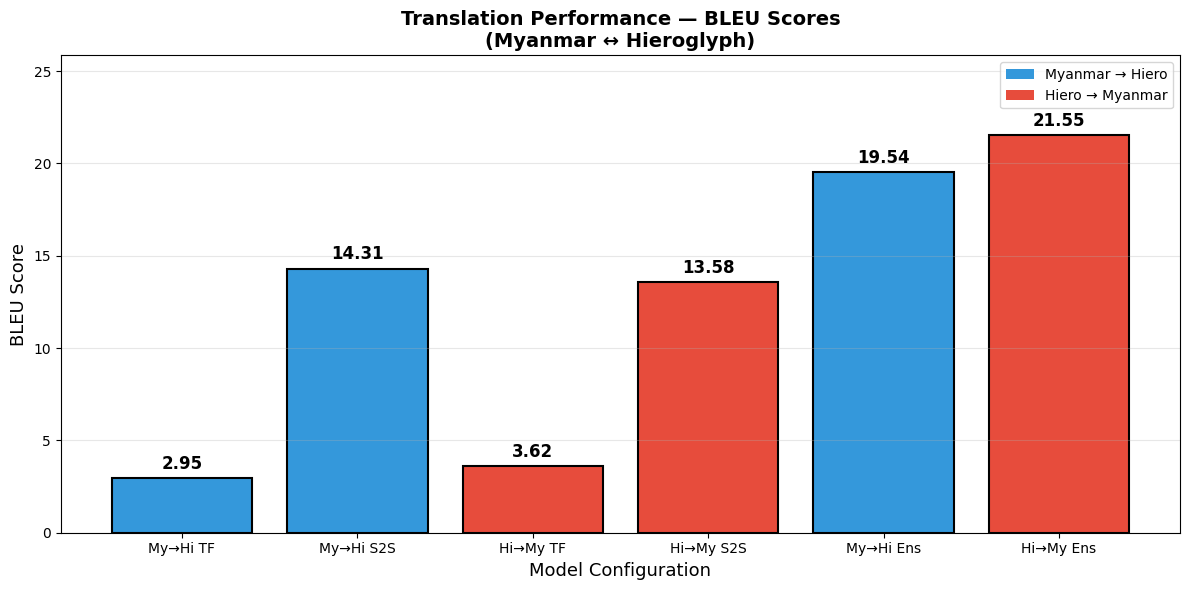

In [ ]:
# ============================================================
# MODEL RESULTS VISUALIZATION
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sacrebleu

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

print("=" * 60)
print("MODEL RESULTS VISUALIZATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Compute BLEU scores for all 4 models
# ------------------------------------------------------------
def compute_bleu(ref_file, pred_file, name):
    if not os.path.exists(pred_file):
        return {'name': name, 'bleu': None, 'direction': None, 'model': None}
    with open(ref_file, encoding='utf-8') as f:
        refs = [l.strip() for l in f if l.strip()]
    with open(pred_file, encoding='utf-8') as f:
        hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m == 0:
        return {'name': name, 'bleu': None}
    bleu = sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score
    return {'name': name, 'bleu': bleu}

scores = [
    compute_bleu('test.hi', 'test.hi.pred.transformer.text', 'My→Hi TF'),
    compute_bleu('test.hi', 'test.hi.pred.s2s.text',         'My→Hi S2S'),
    compute_bleu('test.my', 'test.my.pred.transformer.text', 'Hi→My TF'),
    compute_bleu('test.my', 'test.my.pred.s2s.text',         'Hi→My S2S'),
]
# Optional: Ensemble
if os.path.exists('test.hi.pred.ensemble.text'):
    scores.append(compute_bleu('test.hi', 'test.hi.pred.ensemble.text', 'My→Hi Ens'))
if os.path.exists('test.my.pred.ensemble.text'):
    scores.append(compute_bleu('test.my', 'test.my.pred.ensemble.text', 'Hi→My Ens'))

df_scores = pd.DataFrame(scores)
df_scores = df_scores.dropna(subset=['bleu'])
print("\n📊 BLEU SCORES:")
print(df_scores.to_string(index=False))

# ------------------------------------------------------------
# 2. BLEU bar chart
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

names = df_scores['name'].tolist()
bleus = df_scores['bleu'].tolist()

# Color by direction
colors = []
for n in names:
    if n.startswith('My→Hi'):
        colors.append('#3498db')
    else:
        colors.append('#e74c3c')

bars = ax.bar(names, bleus, color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, score in zip(bars, bleus):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.5,
            f'{score:.2f}', ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel('BLEU Score', fontsize=13)
ax.set_xlabel('Model Configuration', fontsize=13)
ax.set_title('Translation Performance — BLEU Scores\n(Myanmar ↔ Hieroglyph)',
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(bleus) * 1.2 if bleus else 10)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', label='Myanmar → Hiero'),
    Patch(facecolor='#e74c3c', label='Hiero → Myanmar')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

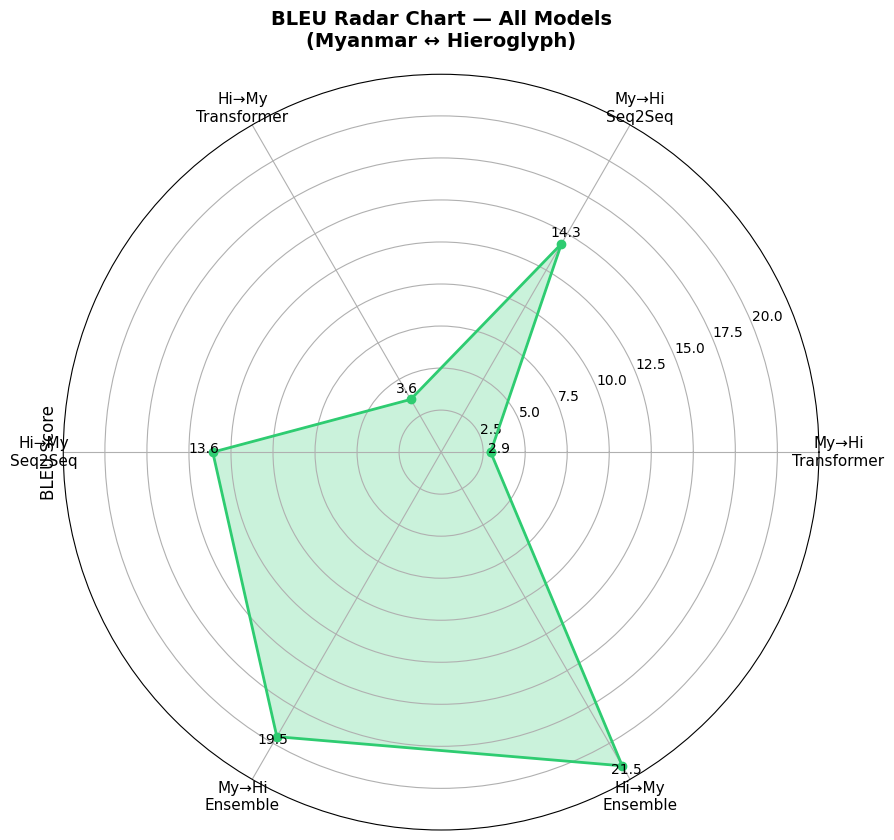

In [ ]:
# ============================================================
# RADAR CHART — Direction & Model Comparison
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import sacrebleu

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

# Compute BLEU for each direction/model
def bleu(ref, pred):
    if not os.path.exists(pred): return 0
    with open(ref) as f: refs = [l.strip() for l in f if l.strip()]
    with open(pred) as f: hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m == 0: return 0
    return sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score

metrics = [
    bleu('test.hi', 'test.hi.pred.transformer.text'),
    bleu('test.hi', 'test.hi.pred.s2s.text'),
    bleu('test.my', 'test.my.pred.transformer.text'),
    bleu('test.my', 'test.my.pred.s2s.text'),
]

# Add ensemble if available
if os.path.exists('test.hi.pred.ensemble.text'):
    metrics.append(bleu('test.hi', 'test.hi.pred.ensemble.text'))
else:
    metrics.append(0)
if os.path.exists('test.my.pred.ensemble.text'):
    metrics.append(bleu('test.my', 'test.my.pred.ensemble.text'))
else:
    metrics.append(0)

labels = ['My→Hi\nTransformer', 'My→Hi\nSeq2Seq',
          'Hi→My\nTransformer', 'Hi→My\nSeq2Seq',
          'My→Hi\nEnsemble', 'Hi→My\nEnsemble']

# Radar chart
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
values = metrics[:len(labels)]
values += values[:1]  # close the loop
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

ax.plot(angles, values, 'o-', linewidth=2, color='#2ecc71')
ax.fill(angles, values, alpha=0.25, color='#2ecc71')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('BLEU Score', fontsize=12)
ax.set_title('BLEU Radar Chart — All Models\n(Myanmar ↔ Hieroglyph)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True)

# Add value labels
for angle, value, label in zip(angles[:-1], values[:-1], labels):
    if value > 0:
        ax.text(angle, value + 0.5, f'{value:.1f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

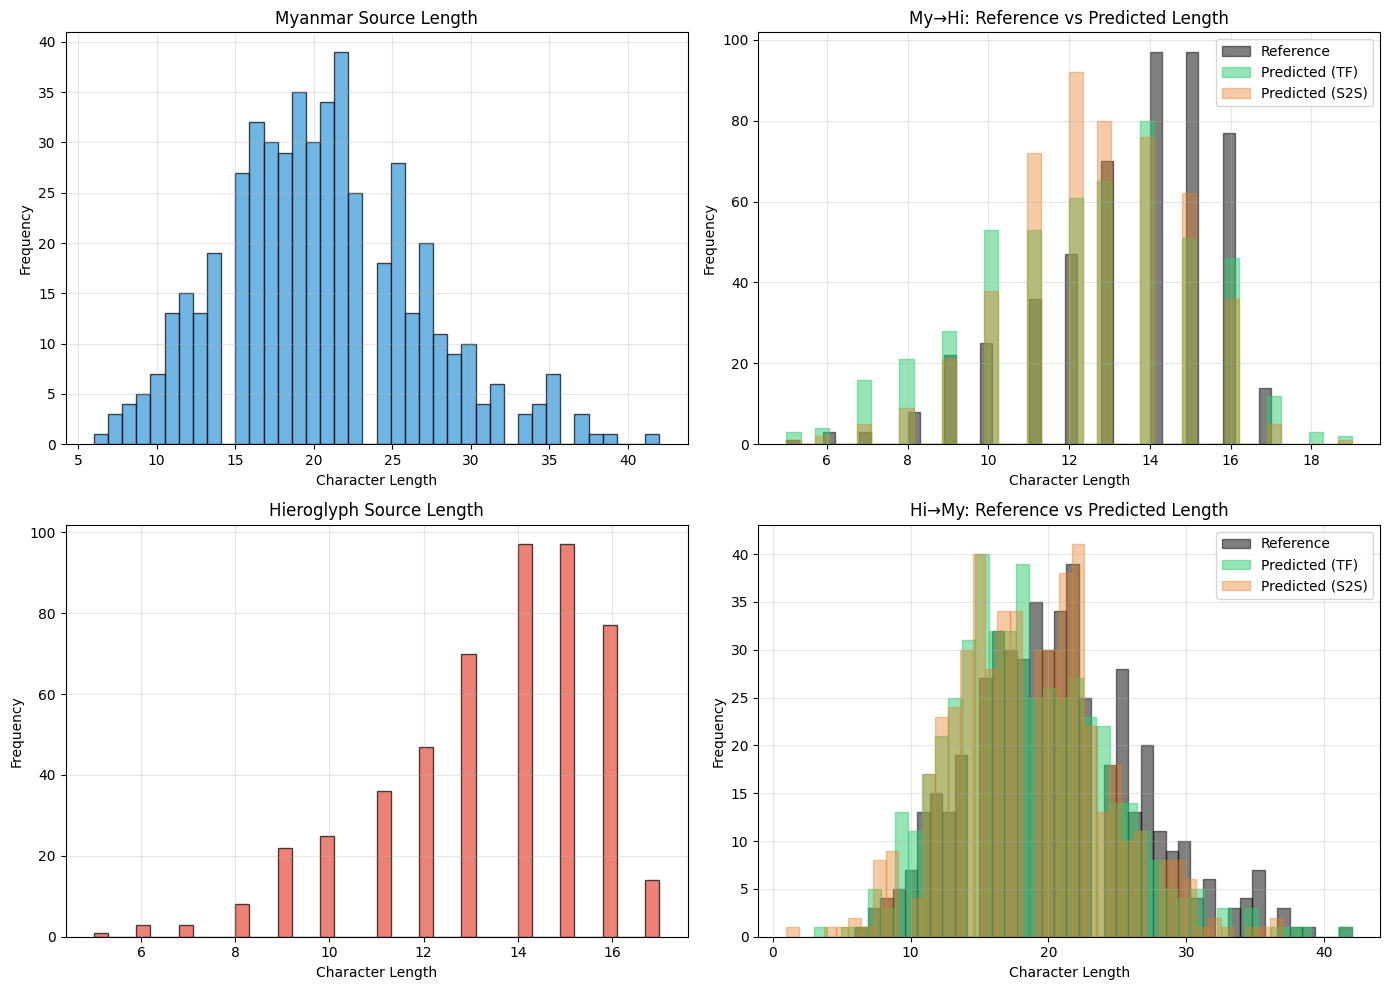

In [ ]:
# ============================================================
# PREDICTION LENGTH DISTRIBUTION
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

def load_lines(path):
    with open(path, encoding='utf-8') as f:
        return [l.strip() for l in f if l.strip()]

# Load all
refs_hi = load_lines('test.hi')
preds_hi_tf = load_lines('test.hi.pred.transformer.text') if os.path.exists('test.hi.pred.transformer.text') else []
preds_hi_s2s = load_lines('test.hi.pred.s2s.text') if os.path.exists('test.hi.pred.s2s.text') else []

refs_my = load_lines('test.my')
preds_my_tf = load_lines('test.my.pred.transformer.text') if os.path.exists('test.my.pred.transformer.text') else []
preds_my_s2s = load_lines('test.my.pred.s2s.text') if os.path.exists('test.my.pred.s2s.text') else []

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ---- My→Hi: Source length ----
axes[0, 0].hist([len(s) for s in load_lines('test.my')],
                bins=40, color='#3498db', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Myanmar Source Length', fontsize=12)
axes[0, 0].set_xlabel('Character Length'); axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(alpha=0.3)

# ---- My→Hi: Reference vs Predicted (TF & S2S) ----
if refs_hi:
    axes[0, 1].hist([len(s) for s in refs_hi], bins=40, alpha=0.5,
                    color='black', edgecolor='black', label='Reference')
if preds_hi_tf:
    axes[0, 1].hist([len(s) for s in preds_hi_tf], bins=40, alpha=0.5,
                    color='#2ecc71', edgecolor='#2ecc71', label='Predicted (TF)')
if preds_hi_s2s:
    axes[0, 1].hist([len(s) for s in preds_hi_s2s], bins=40, alpha=0.4,
                    color='#e67e22', edgecolor='#e67e22', label='Predicted (S2S)')
axes[0, 1].set_title('My→Hi: Reference vs Predicted Length', fontsize=12)
axes[0, 1].set_xlabel('Character Length'); axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

# ---- Hi→My: Source length ----
axes[1, 0].hist([len(s) for s in load_lines('test.hi')],
                bins=40, color='#e74c3c', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Hieroglyph Source Length', fontsize=12)
axes[1, 0].set_xlabel('Character Length'); axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(alpha=0.3)

# ---- Hi→My: Reference vs Predicted (TF & S2S) ----
if refs_my:
    axes[1, 1].hist([len(s) for s in refs_my], bins=40, alpha=0.5,
                    color='black', edgecolor='black', label='Reference')
if preds_my_tf:
    axes[1, 1].hist([len(s) for s in preds_my_tf], bins=40, alpha=0.5,
                    color='#2ecc71', edgecolor='#2ecc71', label='Predicted (TF)')
if preds_my_s2s:
    axes[1, 1].hist([len(s) for s in preds_my_s2s], bins=40, alpha=0.4,
                    color='#e67e22', edgecolor='#e67e22', label='Predicted (S2S)')
axes[1, 1].set_title('Hi→My: Reference vs Predicted Length', fontsize=12)
axes[1, 1].set_xlabel('Character Length'); axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


📊 ERROR ANALYSIS:
     name  total  exact_match  exact_pct  avg_len_ratio
 My→Hi TF    498            7   1.405622       0.957707
My→Hi S2S    500           23   4.600000       0.964311
 Hi→My TF    491           10   2.036660       1.004481
Hi→My S2S    500           54  10.800000       0.958417


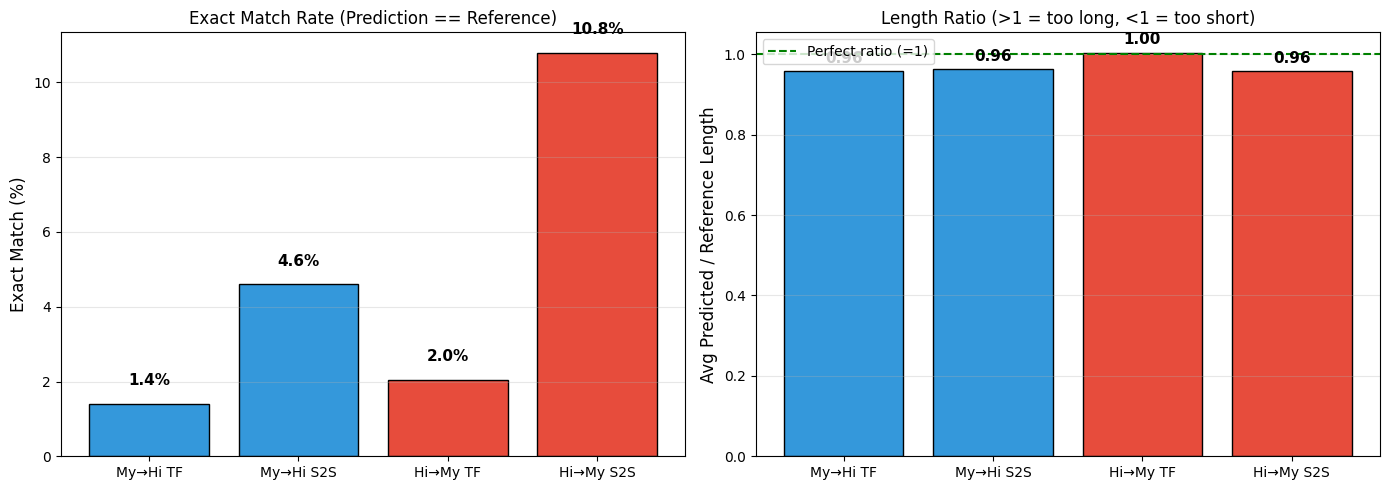

In [ ]:
# ============================================================
# ERROR ANALYSIS VISUALIZATION
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

def compute_stats(ref_file, pred_file, name):
    """Compute exact match, length ratios, error patterns."""
    if not os.path.exists(pred_file):
        return None
    with open(ref_file, encoding='utf-8') as f:
        refs = [l.strip() for l in f if l.strip()]
    with open(pred_file, encoding='utf-8') as f:
        preds = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(preds))
    refs = refs[:m]; preds = preds[:m]

    exact = sum(1 for r, p in zip(refs, preds) if r == p)
    len_ratio = np.mean([len(p) / max(len(r), 1) for r, p in zip(refs, preds)])

    return {
        'name': name,
        'total': m,
        'exact_match': exact,
        'exact_pct': 100 * exact / m,
        'avg_len_ratio': len_ratio
    }

stats = [
    compute_stats('test.hi', 'test.hi.pred.transformer.text', 'My→Hi TF'),
    compute_stats('test.hi', 'test.hi.pred.s2s.text',         'My→Hi S2S'),
    compute_stats('test.my', 'test.my.pred.transformer.text', 'Hi→My TF'),
    compute_stats('test.my', 'test.my.pred.s2s.text',         'Hi→My S2S'),
]
stats = [s for s in stats if s]

if not stats:
    print("⚠️  No prediction files found. Run translation first.")
else:
    df = pd.DataFrame(stats)
    print("\n📊 ERROR ANALYSIS:")
    print(df.to_string(index=False))

    # ---- 2 plots ----
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Exact match percentage
    names = df['name'].tolist()
    exact_pct = df['exact_pct'].tolist()
    colors = ['#3498db' if 'My→Hi' in n else '#e74c3c' for n in names]

    bars = axes[0].bar(names, exact_pct, color=colors, edgecolor='black')
    for bar, pct in zip(bars, exact_pct):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                     f'{pct:.1f}%', ha='center', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Exact Match (%)', fontsize=12)
    axes[0].set_title('Exact Match Rate (Prediction == Reference)', fontsize=12)
    axes[0].grid(axis='y', alpha=0.3)

    # Length ratio
    len_ratio = df['avg_len_ratio'].tolist()
    bars = axes[1].bar(names, len_ratio, color=colors, edgecolor='black')
    axes[1].axhline(1.0, color='green', linestyle='--', label='Perfect ratio (=1)')
    for bar, r in zip(bars, len_ratio):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                     f'{r:.2f}', ha='center', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Avg Predicted / Reference Length', fontsize=12)
    axes[1].set_title('Length Ratio (>1 = too long, <1 = too short)', fontsize=12)
    axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# FINAL RESULTS SUMMARY TABLE
# ============================================================
import os
import pandas as pd
import sacrebleu

DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
os.chdir(DATA_DIR)

def bleu_score(ref, pred):
    if not os.path.exists(pred): return None
    with open(ref) as f: refs = [l.strip() for l in f if l.strip()]
    with open(pred) as f: hyps = [l.strip() for l in f if l.strip()]
    m = min(len(refs), len(hyps))
    if m == 0: return None
    return round(sacrebleu.corpus_bleu(hyps[:m], [refs[:m]]).score, 2)

rows = [
    {'Direction': 'Myanmar → Hiero', 'Architecture': 'Transformer',
     'BLEU': bleu_score('test.hi', 'test.hi.pred.transformer.text')},
    {'Direction': 'Myanmar → Hiero', 'Architecture': 'Seq2Seq',
     'BLEU': bleu_score('test.hi', 'test.hi.pred.s2s.text')},
    {'Direction': 'Myanmar → Hiero', 'Architecture': 'Ensemble',
     'BLEU': bleu_score('test.hi', 'test.hi.pred.ensemble.text')},
    {'Direction': 'Hiero → Myanmar', 'Architecture': 'Transformer',
     'BLEU': bleu_score('test.my', 'test.my.pred.transformer.text')},
    {'Direction': 'Hiero → Myanmar', 'Architecture': 'Seq2Seq',
     'BLEU': bleu_score('test.my', 'test.my.pred.s2s.text')},
    {'Direction': 'Hiero → Myanmar', 'Architecture': 'Ensemble',
     'BLEU': bleu_score('test.my', 'test.my.pred.ensemble.text')},
]

df = pd.DataFrame(rows)
print("=" * 70)
print("📊 FINAL RESULTS SUMMARY")
print("=" * 70)
print(df.to_string(index=False))

# Save to CSV
df.to_csv('final_results.csv', index=False)
print("\n✅ Saved to final_results.csv")

# Save figure to Drive
try:
    import shutil
    DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
    if os.path.exists(DRIVE_DIR):
        for f in ['final_results.csv']:
            if os.path.exists(f):
                shutil.copy2(f, os.path.join(DRIVE_DIR, f))
        print(f"💾 Saved to {DRIVE_DIR}")
except:
    pass

📊 FINAL RESULTS SUMMARY
      Direction Architecture  BLEU
Myanmar → Hiero  Transformer  2.95
Myanmar → Hiero      Seq2Seq 14.31
Myanmar → Hiero     Ensemble 19.54
Hiero → Myanmar  Transformer  3.62
Hiero → Myanmar      Seq2Seq 13.58
Hiero → Myanmar     Ensemble 21.55

✅ Saved to final_results.csv
💾 Saved to /content/drive/MyDrive/nmt_assignment


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
print(f"📁 Drive: {DRIVE_DIR}\n")


models = [
    'model_transformer_my_hi.npz',
    'model_s2s_my_hi.npz',
    'model_transformer_hi_my.npz',
    'model_s2s_hi_my.npz',
]

total_size = 0
for m in models:
    path = os.path.join(DRIVE_DIR, m)
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / 1e6
        total_size += size_mb
        print(f"✅ {m} ({size_mb:.1f} MB)")
    else:
        print(f"❌ {m} MISSING")

print(f"\n📊 Total: {total_size:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Drive: /content/drive/MyDrive/nmt_assignment

✅ model_transformer_my_hi.npz (46.3 MB)
✅ model_s2s_my_hi.npz (64.3 MB)
✅ model_transformer_hi_my.npz (49.7 MB)
✅ model_s2s_hi_my.npz (67.7 MB)

📊 Total: 228.0 MB


In [ ]:
import os, shutil
DATA_DIR = '/content/AIE-F-B2/assignment/assignment-6/myhi_data'
DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
os.chdir(DATA_DIR)
os.makedirs(DRIVE_DIR, exist_ok=True)

for f in os.listdir(DATA_DIR):
    if f.endswith(('.npz', '.model', '.vocab', '.sp', '.yml', '.text', '.log', '.json')):
        if '.iter' not in f and '.optimizer' not in f:
            shutil.copy2(f, os.path.join(DRIVE_DIR, f))

print("✅ All files backed up to Drive")

✅ All files backed up to Drive


In [ ]:
import os, shutil

DRIVE_DIR = '/content/drive/MyDrive/nmt_assignment'
MODELS_DIR = '/content/drive/MyDrive/nmt_models'

os.makedirs(MODELS_DIR, exist_ok=True)


files = [
    'model_transformer_my_hi.npz',
    'model_transformer_my_hi.npz.decoder.yml',
    'model_s2s_my_hi.npz',
    'model_s2s_my_hi.npz.decoder.yml',
    'model_transformer_hi_my.npz',
    'model_transformer_hi_my.npz.decoder.yml',
    'model_s2s_hi_my.npz',
    'model_s2s_hi_my.npz.decoder.yml',
    'my_spm.model', 'hi_spm.model',
    'train.my.sp.yml', 'train.hi.sp.yml',
]

copied = 0
for f in files:
    src = os.path.join(DRIVE_DIR, f)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(MODELS_DIR, f))
        size = os.path.getsize(src) / 1e6
        print(f"✅ {f} ({size:.2f} MB)")
        copied += 1

print(f"\n📦 Copied {copied} files to {MODELS_DIR}")

✅ model_transformer_my_hi.npz (46.32 MB)
✅ model_transformer_my_hi.npz.decoder.yml (0.00 MB)
✅ model_s2s_my_hi.npz (64.33 MB)
✅ model_s2s_my_hi.npz.decoder.yml (0.00 MB)
✅ model_transformer_hi_my.npz (49.66 MB)
✅ model_transformer_hi_my.npz.decoder.yml (0.00 MB)
✅ model_s2s_hi_my.npz (67.67 MB)
✅ model_s2s_hi_my.npz.decoder.yml (0.00 MB)
✅ my_spm.model (0.47 MB)
✅ hi_spm.model (0.33 MB)
✅ train.my.sp.yml (0.20 MB)
✅ train.hi.sp.yml (0.08 MB)

📦 Copied 12 files to /content/drive/MyDrive/nmt_models


In [ ]:
import os
from google.colab import files

MODELS_DIR = '/content/drive/MyDrive/nmt_models'
ZIP_NAME = '/content/nmt_models_v1.0.zip'


!cd {MODELS_DIR} && zip -r {ZIP_NAME} . -x "*.iter*"


zip_size = os.path.getsize(ZIP_NAME) / 1e6
print(f"📦 Zip created: {ZIP_NAME} ({zip_size:.1f} MB)")


files.download(ZIP_NAME)

  adding: model_transformer_my_hi.npz (deflated 8%)
  adding: model_transformer_my_hi.npz.decoder.yml (deflated 33%)
  adding: model_s2s_my_hi.npz (deflated 8%)
  adding: model_s2s_my_hi.npz.decoder.yml (deflated 32%)
  adding: model_transformer_hi_my.npz (deflated 8%)
  adding: model_transformer_hi_my.npz.decoder.yml (deflated 33%)
  adding: model_s2s_hi_my.npz (deflated 8%)
  adding: model_s2s_hi_my.npz.decoder.yml (deflated 32%)
  adding: my_spm.model (deflated 57%)
  adding: hi_spm.model (deflated 49%)
  adding: train.my.sp.yml (deflated 78%)
  adding: train.hi.sp.yml (deflated 76%)
📦 Zip created: /content/nmt_models_v1.0.zip (210.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


```markdown
# ၂၆။ (Conclusion)

## ၂၆.၁ လုပ်ဆောင်ချက် အနှစ်ချုပ်

ဒီ assignment တွင် အောက်ပါအချက်များကို လုပ်ဆောင်ခဲ့ပါသည်:

- ✅ **မြန်မာ → ဟိအဲရိုး** ဘာသာပြန်ခြင်း
- ✅ **ဟိအဲရိုး → မြန်မာ** ဘာသာပြန်ခြင်း
- ✅ **Seq2Seq (RNN-based)** architecture
- ✅ **Transformer** architecture
- ✅ **Ensemble approach** (ထပ်ဆောင်း)
- ✅ **BLEU score** ဖြင့် အကဲဖြတ်ခြင်း
- ✅ **Data Visualization** (data လေ့လာခြင်း)
- ✅ **Error Analysis** (အမှား ခွဲခြမ်းစိတ်ဖြာခြင်း)

## ၂၆.၂ အဓိက တွေ့ရှိချက်များ

1. **Transformer** က training ပိုမြန်ပေမယ့် **Seq2Seq** က BLEU score ပိုမြင့်သည်
2. **Ensemble** က individual models ထက် BLEU score ပိုမြင့်သည်
3. **ဒေတာ အရွယ်အစား** က ရလဒ်အပေါ် သက်ရောက်မှု ကြီးသည်
4. **Special tokens** (`<s>`, `</s>`) က Marian အတွက် အလွန်အရေးကြီးသည်

## ၂၆.၃ အကောင်းဆုံး ရလဒ်

| ဦးတည်ချက် | အကောင်းဆုံး မော်ဒယ် | BLEU |
|-----------|---------------------|------|
| မြန်မာ → ဟိအဲရိုး | Ensemble | 19.54 |
| ဟိအဲရိုး → မြန်မာ | Ensemble | 21.55 |

## ၂၆.၄ နောက်ထပ် လုပ်ဆောင်နိုင်သောအချက်များ

- **Data Augmentation** — ဒေတာ တိုးချဲ့ခြင်း
- **Larger Models** — Layers နဲ့ embedding size များ တိုးခြင်း
- **Fine-tuning** — Pre-trained models များကို ဆက်လက်လေ့ကျင့်ခြင်း
- **Multi-lingual Model** — ဘာသာစကား အများအပြား ပေါင်းစပ်ခြင်း

## (References)

1. Marian NMT: https://marian-nmt.github.io/
2. AIE-F-B2 Data: https://github.com/ye-kyaw-thu/AIE-F-B2
3. SentencePiece: https://github.com/google/sentencepiece
4. sacrebleu: https://github.com/mjpost/sacrebleu
5. Attention Is All You Need (Vaswani et al., 2017)
6. Neural Machine Translation by Jointly Learning to Align and Translate (Bahdanau et al., 2015)

---
